# INM707-Deep-Learning Coursework: Bernardo Saab & James Ashdown



    ### Actions ###
    
      - 0: move down
      - 1: move up
      - 2: move left
      - 3: move right
      - 4: pickup hostage
      - 5: drop hostage
      - 6: open door
    
    ### States ###
    
    There are 800 maximum possible states 10x10 matrix x2 open door x2 pickup hostage x2 drop hostage
    There are walls inside the grid which receieve negative rewards if you turn into them. 
    The agent cannot move into a wall and therefore the state space is actually smaller in this regard (800-wall states)
    
    There are some special cells which the agent has to visit and perform specific actions these are:
    
    1) Pickup Hostage in Hostage Zone
    2) Pickup Key in Key Zone
    3) Open Door and Drop Hostage in Safe Zone 
    
    The Safe Zone is a terminal state and maximum reward occurs if the Agent has a key and hostage which is dropped in the safe zone
    
    There are two other scenarios the agent has to avoid:
    
    4) Entering a Mine near the Safe Zone - This is a terminal state
    5) Entering an Unsafe zone and dropping off the hostages - This is also a terminal state.    
    
    ### Epochs & Episodes ###
    
    The agent is allowed to traverse the state space ~ 200 times in a given episode
    We have allowed for a maximum of 100k episodes for the agent to learn an optimal solution
    Of course these are both parameters that are observeed and fine tuned during the training process
    Using a standard Q learning approach means that convergence can take quite some time. The agent is randomly 
    assigned to a new state after each episode and it has been observed the closer the agent is positioned near
    the key the faster the convergence of the algorithm
    
    ### Q LEarning ###
    
    The agent utilises Q learning and follows an episolon greedy approach with a decay function so that it starts off
    in an exploratory manner and the more it learns it takes a greedy approach for optimal reward. These parameters along with 
    learning rate are tested in a randomised grid search to ensure optimal performance. Average cumlative rewards by steps and 
    actions are plotted to find optimal plateaus on the minimum number of steps required to converge for each hyper parameter.
    
   

In [68]:
import matplotlib.pyplot as plt
import time 
import numpy as np
import pandas as pd
import random
import argparse

# Main class

In [335]:
#These are the key actions you can apply at states
action_dict = {
    0: 'up',
    1: 'down',
    2: 'right',
    3: 'left',
    4: 'pickup',
    5: 'dropoff',
    6: 'open'
}

#Colours for environment
color2num = dict(
    gray=30,
    red=31,
    green=32,
    yellow=33,
    blue=34,
    magenta=35,
    cyan=36,
    white=37,
    crimson=38,
)

#Function to surround string with certain colour codes
def colorize(string, color, bold=False, highlight=False):
    attr = []
    num = color2num[color]
    if highlight:
        num += 10
    attr.append(str(num))
    if bold:
        attr.append("1")
    attrs = ";".join(attr)
    return f"\x1b[{attrs}m{string}\x1b[0m"

# A function that counts the number of true values when the cumulative sum of n probabilities
#In an array is greater than a randomly generated number used in the step function

def categorical_sample(prob_n, np_random):
    prob_n = np.asarray(prob_n)
    csprob_n = np.cumsum(prob_n)
    return (csprob_n > np_random.random()).argmax()

class MapWalkingEnv:

    def __init__(self, N, M):
        # Numpy array that holds the information about the environment
        self.territory = np.zeros((N, M), dtype = np.int8)
        self.height = N
        self.width = M
        self.size = N * M 
        self.average_size = round((N+M)/2,0)
        self.hostage = 1 # 1 hostage zones
        self.exit = 2 # 1 safe zone and 1 unsafe
        
        # Number of random objects
        self.number_keys = 1
        self.number_hostages = 1
        self.number_mines = 1
        self.exit_steps = None 

        # Define Walls
        wall_states = [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)]
        
        for i,j in wall_states:
            self.territory[i,j] = 1
        
        # Pick 1 random coordinates for the mine
        self.mine_coord = mine_coord = (0,9)
        self.territory[mine_coord[0], mine_coord[1]] = 2

        # Pick 2 random coordinatesto be safe zone and unsafe zone
        self.exit_coord = exit_coord = self.get_exit_cells(self.exit)
        self.exit_coord = exit_coord = ((0,8),(9,9))  #Debugging purposes (initial seed)
        self.territory[exit_coord[0][0], exit_coord[0][1]] = 5 # Safe
        self.territory[exit_coord[1][0], exit_coord[1][1]] = 6 # Unsafe
        
        # Pick 1 random coordinate for the key
        self.key_coord = key_coord = self.get_empty_cells(self.number_keys)
        self.key_coord = key_coord = (5,7) #Debugging purposes (initial seed)
        self.territory[key_coord[0],key_coord[1]] = 3
         
        # Pick 1 random coordinate for the hostage zone
        self.hostage_coord = hostage_coord = self.get_empty_cells(self.number_hostages)
        self.hostage_coord = hostage_coord = (9,8) #(9,6) #(2,4) #Debugging purposes (initial seed)
        self.territory[hostage_coord[0],hostage_coord[1]] = 4
        
        # initial position of the agent will be decided by resetting the environment.
        self.position_agent = None
        self.start_agent = None

        # run time
        self.time_elapsed = 0
        self.time_limit = 2*self.size #* 8

        # display help
        self.dict_map_display={ 0:'.', #0 : empty cell
                                1:'X', #1 : walls obstacle that are non-traversable
                                2:'M', #2 : mine field location
                                3:'K', #3 : key location
                                4:'H', #3 : hostage zone    
                                5:'S', #4 : safe zone
                                6:'U', #6 : unsafe zone
                                7:'A' #7 : agent location
                              }
       

        num_states = self.size * 8
        num_rows = N
        num_columns = M
        max_row = num_rows - 1
        max_col = num_columns - 1
        self.initial_state_distrib = np.zeros(num_states)
        num_actions = 7
        
        # Set available actions
        self.actions = [0,1,2,3,4,5,6]
        #self.actions = ['up','down','left','right','pickup','dropoff','open']
        
        self.P = {
            state: {action: [] for action in range(num_actions)}
            for state in range(num_states)
        }
        self.states_array = {
            state   : {}
            for state in range(num_states)
        }
        self.observations_array = {
            state   : {}
            for state in range(num_states)
        }
        
        # Create matrix of possible transitions, essentially like R matrix
        for row in range(num_rows): #7
            for col in range(num_columns): #7
                for key_idx in range(2): # +1 for key being with agent
                    for host_idx in range(2): # +1 for host being with agent
                        for exit_idx in range(2): # for tracking if door was opened or not
                            state = self.encode(row, col, key_idx, host_idx, exit_idx)
                            #if state == 69:
                            #    print(row, col, key_idx, host_idx, exit_idx)
                             
                            if  (self.territory[row, col] != 1) \
                                and self.territory[row, col] != 2 \
                                and (key_idx < 1 and host_idx < 1 and exit_idx < 1):
                                self.initial_state_distrib[state] += 1
                                self.states_array[state] = (row, col)
                            if  self.territory[row, col] != 1: 
                                self.observations_array[state] = (row, col)
                            
                            valid_actions = self.valid_actions(row, col)
                            
                            for action in valid_actions:
                                # defaults
                                new_row, new_col, new_key_idx, new_host_idx, new_exit_idx=row, col, key_idx, host_idx, exit_idx
                                reward = (
                                    0 #-0.1
                                )  # Default reward when there is no pickup/dropoff/open and agent moves to an open cell
                                
                                done = False
                                agent_loc = (row, col)
                                

                                if action == 0: #'up' 
                                    new_row = max(row - 1, 0)
                                elif action == 1: #'down' 
                                    new_row = min(row + 1, max_row)
                                elif action == 2: #'right' 
                                    new_col = min(col + 1, max_col)
                                elif action == 3: #'left':
                                    new_col = max(col - 1, 0)
                                elif action == 4: #'pickup' 
                                    if new_host_idx == 0 and new_key_idx == 1 and new_exit_idx == 1 and \
                                    (agent_loc == (hostage_coord[0],hostage_coord[1])):
                                        new_host_idx = 1
                                        reward = 20
                                    elif new_key_idx == 0 and (agent_loc == (key_coord[0],key_coord[1])):
                                        new_key_idx = 1
                                        reward = 20
                                    elif self.territory[new_row, new_col] != 2: # key not at location or agent did not open a door yet
                                        reward = -20
                                elif action == 5: #'dropoff' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1]) and \
                                        new_key_idx == 1 and new_host_idx == 1):
                                        done = True
                                        reward = 100
                                    elif agent_loc == (exit_coord[1][0],exit_coord[1][1]) : #(agent_loc == (exit_coord[0][0],exit_coord[0][1]) and (new_key_idx == 0)) or \
                                        done = True
                                        reward = -100
                                    elif self.territory[new_row, new_col] != 2:  # dropoff at wrong location
                                        reward = -20
                                elif action == 6: #'open' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1])) and (new_key_idx == 1 and new_exit_idx == 0):
                                        new_exit_idx = 1
                                        #reward = 20
                                    elif self.territory[new_row, new_col] != 2:  # open at wrong location
                                        reward = -20

                                if (new_host_idx == 1 and new_key_idx == 1) or \
                                    new_exit_idx == 1:
                                    new_exit_idx=1
                                else:
                                    new_exit_idx=0
                                    
                                # If the agent bumps into a wall, it doesn't move
                                if self.territory[new_row, new_col] == 1:
                                    new_row = row
                                    new_col = col
                                    reward = -10
                                
                                # If the agent bumps into a mine it reaches a terminal state:
                                if self.territory[new_row, new_col] == 2:
                                    new_row = row
                                    new_col = col
                                    done = True
                                    reward = -100 

                                if self.territory[row, col] != 1 and self.territory[row, col] != 2:
                                    new_state = self.encode(
                                        new_row, new_col, new_key_idx, new_host_idx, new_exit_idx
                                    )
                                    
                                    self.P[state][action].append((1.0, new_state, reward, done))
                       
        self.initial_state_distrib /= self.initial_state_distrib.sum()
        self.action_space = int(num_actions)
        self.observation_space = int(num_states)
        self.state_space = int(num_states)
    
    def get_empty_cells(self, n_cells):
        empty_cells_coord = np.where( self.territory == 0 )
        selected_indices = np.random.choice( np.arange(len(empty_cells_coord[0])), n_cells )
        selected_coordinates = empty_cells_coord[0][selected_indices], empty_cells_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
        
    def get_exit_cells(self, n_cells):
        y=np.arange(self.territory.shape[0] * self.territory.shape[1]).reshape(self.territory.shape[0], self.territory.shape[1])        
        border_coord_indices = list(np.unique(np.array(sorted(np.concatenate([y[0,:],y[-1,:],y[:,0], y[:,-1]]))).reshape(1,-1)))
        border_coord=np.zeros((2,len(border_coord_indices)),dtype = np.int8)
        border_coord[0] = [int(i) for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        border_coord[1] = [j for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        #print(border_coord_indices)
        #print(border_coord)
        selected_indices = np.random.choice( np.arange(len(border_coord[0])), n_cells )
        selected_coordinates = border_coord[0][selected_indices], border_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
    
    
    # a key function for the q learning update rule
    def step(self, action):
        
        transitions = self.P[self.s][action]
        i = categorical_sample([t[0] for t in transitions], np.random)
        p, state, reward, done = transitions[i]
        self.s = state
        self.lastaction = action
        
        if done == False:
            self.position_agent = (self.observations_array[self.s][0],self.observations_array[self.s][1])

        # Update time elapsed
        self.time_elapsed+=1
        
        _, _, _, _, self.exit_steps = env.decode(env.s)

        if self.time_elapsed == self.time_limit:
            done = True
        
        return (int(state), reward, done, {"prob": p})
   

    def agent_on_map(self):
        #prints out current location of agent on the grid
        grid = np.zeros((self.N, self.M))
        grid[ self.current_location[0], self.current_location[1]] = 1
        return grid
    
    
    def encode(self, agent_row, agent_col, key_idx, host_idx, exit_idx):
        i = agent_row
        i *= 10
        i += agent_col
        i *= 2
        i += key_idx
        i *= 2
        i += host_idx
        i *= 2
        i += exit_idx
        return i

    def decode(self, i):
        out = []
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 10)
        i = i // 10
        out.append(i)
        assert 0 <= i < 10
        return reversed(out)
    
    
    def display(self, mode='human'):
 
        envir_with_agent = self.territory.copy()
        envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        #envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        
        agent_row, agent_col, key_idx, host_idx, exit_idx = self.decode(self.s)

        full_repr = ""

        for r in range(self.height):
            
            line = ""
            
            for c in range(self.width):
                
                string_repr = self.dict_map_display[ envir_with_agent[r,c] ]
                line += "{0:2}".format(string_repr)

            full_repr += line + "\n"
        
        if key_idx == 1 and exit_idx == 0: # Agent found the key but did not open the door yet
            full_repr = full_repr.replace('A',colorize('A', "yellow", highlight=True))
        elif exit_idx == 1 and host_idx == 0: # Agent opened the door but did not find hostage
            full_repr = full_repr.replace('A',colorize('A', "blue", highlight=True))
        elif host_idx == 1: # Agent found the hostage
            full_repr = full_repr.replace('A',colorize('A', "green", highlight=True))

        print('Key (Yellow):',key_idx,'/ Door (Blue):',exit_idx,'/ Hostage (Green):',host_idx,'- Agent start',self.start_agent)
        print(full_repr)

        
    def calculate_observations(self):
        
        relative_coordinates = self.position_exit - self.position_agent
                
        surroundings = self.territory[ self.position_agent[0] -1: self.position_agent[0] +2,
                                     self.position_agent[1] -1: self.position_agent[1] +2]
        
        obs = {'relative_coordinates':relative_coordinates,
               'surroundings': surroundings}
        
        return obs
        
    def reset(self, return_info: bool = False):
        #This function resets the environment for the agent
        self.time_elapsed = 0
         
        invalid_position = True                                    


        while invalid_position == True:
            self.s = categorical_sample(self.initial_state_distrib, np.random)
            new_coord = self.states_array[self.s]
            #print(new_coord)
            if      ((new_coord[0],new_coord[1]) != (self.exit_coord[0][0],self.exit_coord[0][1])) \
                and ((new_coord[0],new_coord[1]) != (self.exit_coord[1][0],self.exit_coord[1][1])) \
                and ((new_coord[0],new_coord[1]) != (self.hostage_coord[0],self.hostage_coord[1])) \
                and ((new_coord[0],new_coord[1]) != (self.key_coord[0],self.key_coord[1])):
                invalid_position = False
                self.position_agent = (new_coord[0],new_coord[1])
        
        #self.position_agent = (6,9)
        self.start_agent = self.position_agent
        

        self.lastaction = None
        if not return_info:
            return int(self.s)
        else:
            return int(self.s), {"prob": 1}
        #return observations
        
        
    def valid_actions(self, row=None, col=None, cell=None):
        actions = [0, 1, 2, 3, 4, 5, 6]
        if (row == None and col == None):
            row = self.observations_array[self.s][0]
            col = self.observations_array[self.s][1]

        nrows, ncols = self.territory.shape
        if row == 0:
            actions.remove(0)
        elif row == nrows-1:
            actions.remove(1)

        if col == 0:
            actions.remove(3)
        elif col == ncols-1:
            actions.remove(2)
            
        return actions

# Q-Learning Training

In [483]:
%%time
"""Training the agent"""

"""Grid Search Parameters:""

Alpha Values: 0.9,0.1
Gamma Values: 0.8,0.5
Epsilon Values: 0.9,0.5

"""
from IPython.display import clear_output

# Variables
N = 10
M = 10
episodes = 100000

# Hyperparameters
alpha = 0.9 #0.1 or 0.9
gamma = 0.8 #0.5 or 0.8

# Exploration rate.
epsilon = 0.5 #0.5 ot 0.9

# Exploration decay rate.
DECAY_RATE = 0.95 #0.9998          

# For plotting metrics
all_epochs = []
all_rewards = []
dropoff_epochs = []
dropoff_rewards = []
pickup_epochs = []
pickup_rewards = []
open_epochs = []
open_rewards = []
state_count1000f =[]
state_count1000l =[]

env = MapWalkingEnv(N,M)

Q = np.zeros([env.state_space, env.action_space])

for i in range(1, episodes):
    #reset the environment start of each episode being looped and randomly allocate agent
    state = env.reset()
    #reset the epoch steps to 0 and rewards to 0
    epochs, reward, cumreward, epochs_pickup, cumreward_pickup, epochs_dropoff, cumreward_dropoff, epochs_open, cumreward_open  = 0, 0, 0, 0, 0, 0, 0, 0, 0
    #reset terminal status to false
    done = False
    #reset number of epoch steps taken to terminal status to 0
    exit_num_steps = 0
    
    #while in new episode and not a terminal state 
    while not done:
        #define the valid actions that are allowed from the map walking environment
        valid_actions = env.valid_actions()
        # if there is an error with valid actions re run the step but there shouldnt be
        if not valid_actions: break
        # if a random number between 0 and 1 is less than our epsilon greedy value then Explore the space
        if random.uniform(0, 1) < epsilon: ################### HYPER PARAMETER ###################
            #Do this by taking a random choice of the list of valid actions at this step
            action = np.random.choice(valid_actions)
        else:
            #Otherwise set an action value array
            action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
            #For each action 0 to 6 in the Q matrix for a given state
            for action,value in enumerate(Q[state]):
                #If the action is a valid action for this step
                if action in valid_actions:
                    #Then calculate action_value for taking that action, this value in the Q matrix is a.k.a expected reward
                    action_value[action] = value
            #Once we know the expected rewards for all the valid actions we now take a greedy approach and 
            #Select the action which gives the maximum reward a.k.a Exploiting the learned values in the Q matrix
            action = np.random.choice(np.flatnonzero(action_value == action_value.max()))
        
        #Once we have selected an action we take it and observe the instant reward if there is one and the next state position
        next_state, reward, done, info = env.step(action) 
        
        ## Update the Q value ##
        
        #save existing value
        old_value = Q[state, action]
        #figure out what the maximum action value is from the next state, which could be better than what we arleady expected
        next_max = np.max(Q[next_state])
        # update the current state action pair using the q learning update rule which utilises the knowledge of the next state
        # which may have exploited prior knowledge or have gone in a random direction and learnt something new, which in turn
        # may have updated the current state expected reward if a higher reward was available going in the random direction
        #this in turn will allow better exploitation in the next episode as the algorithm learns the best states and actions to take
        new_value = old_value + alpha * ((reward + gamma * next_max) - old_value) ###### HYPER PARAMETERS ########
        Q[state, action] = new_value
        
        #calculate number of steps taken in the episode before exit
        if env.exit_steps == 1:
            exit_num_steps  = epochs  
            
        #pickup
        if action == 4:
            epochs_pickup = epochs
            cumreward_pickup = cumreward
            
        #dropoff
        if action == 5:
            epochs_dropoff = epochs
            cumreward_dropoff = cumreward
            
        #open
        if action == 6:
            epochs_open = epochs
            cumreward_open = cumreward
            
        # go to the next state
        state = next_state
        
        #update the cumulative epochs and rewards
        epochs += 1
        cumreward += reward
        

    # if epsilon is > 0.15 then keep decaying otherwise just keep it at 0.15 to always maintain some exploration
    # this is because the state action space is quite large and want to ensure as many actions are taken as possible
    if epsilon > 0.15:
        epsilon *= DECAY_RATE                 # Decaying the exploration rate every episode.
    else:
        epsilon = 0.15
    
    all_epochs.append(epochs)
    all_rewards.append(cumreward)
    pickup_epochs.append(epochs_pickup)
    pickup_rewards.append(cumreward_pickup)
    dropoff_epochs.append(epochs_dropoff)
    dropoff_rewards.append(cumreward_dropoff)
    open_epochs.append(epochs_open)
    open_rewards.append(cumreward_open)
    
    if i < 1001:
        state1000f=state
        
    if i > 99000:
        state1000l=state
    
    state_count1000f.append(state1000f)
    state_count1000l.append(state1000l)
    
    #outputs visual of the environment at every X episodes shwoing where the agent is
    if i % 100 == 0:
        clear_output(wait=True)
        print(f"Episode: {i}")
        env.display()
        print('Time Elapsed:',env.time_elapsed,'-','State:',env.s,'-','Action:',action_dict[action],'-','Reward:',reward,
        print('Steps to open door:',exit_num_steps, '-','Steps to complete:',exit_num_steps))
        
print("Training finished.\n")

Episode: 99900
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (1, 4)
. X . . . . . . A M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . . X H U 

Steps to open door: 96 - Steps to complete: 96
Time Elapsed: 97 - State: 71 - Action: dropoff - Reward: 100 None
Training finished.

Wall time: 13min 39s


In [516]:
np.unique(pd.DataFrame(state_count1000f).tail(90000))


array([692], dtype=int64)

In [505]:
np.unique(pd.DataFrame(state_count1000l).head(90000))

array([0], dtype=int64)

In [522]:
#run this twice and get two graphs out
SC1000=np.unique(state_count1000f[0:1000], return_counts=True)
SC100000=np.unique(state_count1000l[99000:], return_counts=True)
SC100000

(array([ 64,  68,  69,  71, 152, 156, 157, 159, 797, 799]),
 array([  2,  28,  32, 912,   1,   7,  11,   3,   2,   1], dtype=int64))

In [523]:
SC1000

(array([  4,   5,  20,  21,  28,  29,  36,  37,  44,  45,  52,  53,  60,
         61,  64,  68,  69,  80,  84,  85,  92,  93, 100, 101, 108, 109,
        112, 116, 117, 132, 133, 140, 141, 148, 149, 152, 156, 157, 164,
        165, 172, 173, 180, 181, 188, 189, 196, 212, 213, 216, 220, 221,
        228, 229, 236, 237, 261, 284, 296, 300, 301, 308, 309, 316, 317,
        324, 332, 333, 348, 364, 365, 396, 404, 412, 413, 428, 429, 444,
        445, 452, 453, 460, 461, 468, 469, 476, 477, 484, 485, 488, 492,
        496, 500, 501, 508, 509, 516, 517, 524, 525, 532, 533, 540, 541,
        548, 549, 556, 557, 564, 572, 580, 581, 584, 588, 589, 596, 597,
        604, 605, 644, 692, 700, 704, 708, 716, 724, 732, 740, 744, 748,
        756, 760, 764, 768, 772, 788, 792, 796]),
 array([ 2,  1,  1,  4,  5,  6,  5,  6,  2,  2,  6,  6,  5,  6,  3, 20, 37,
         1,  3,  2,  6,  6,  4,  6,  7,  2,  1,  5,  4,  1,  8,  4,  5,  7,
         8,  1, 27, 17,  3,  2,  2,  3,  1,  6,  2,  5,  2,  6,  2, 

<AxesSubplot:>

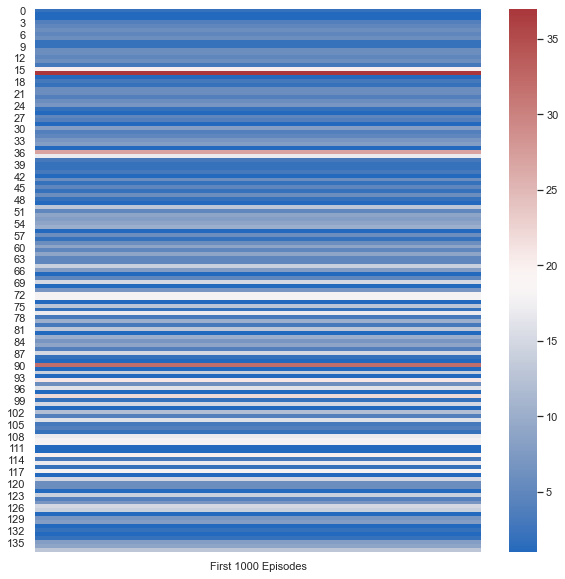

In [529]:
SCDF1000=pd.DataFrame(SC1000[1]).rename(columns={0:'First 1000 Episodes'})
sns.set(font_scale=1)
plt.figure(figsize=(10, 10))
sns.heatmap(SCDF1000,  cmap= 'vlag')

<AxesSubplot:>

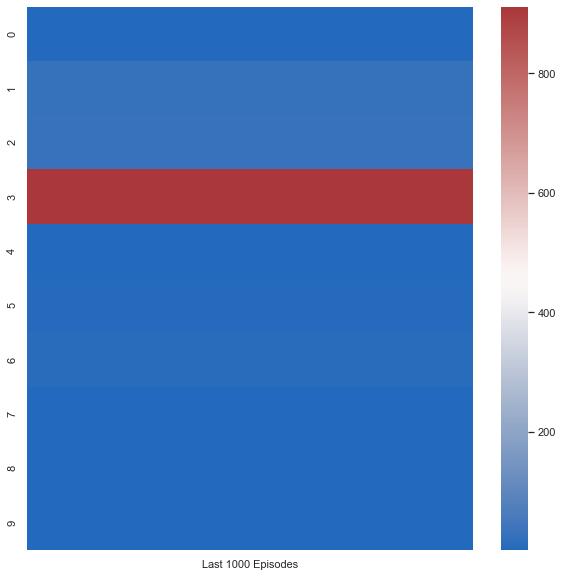

In [530]:
SCDF100000=pd.DataFrame(SC100000[1]).rename(columns={0:'Last 1000 Episodes'})
sns.set(font_scale=1)
plt.figure(figsize=(10, 10))
sns.heatmap(SCDF100000, cmap= 'vlag')

# Training Results

In [ ]:
#Base Scenario alpha=0.9,gamma=0.8,epsilon=0.9 WALLTIME = 12 Minutes
#avgcumrewards=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#BaseOutput=pd.DataFrame(avgcumrewards)
#BaseOutput.to_csv('Base_09_08_09.csv')

In [ ]:
#Tune 1 alpha=0.1,gamma=0.8,epsilon=0.9 WALLTIME = 13 mins
#avgcumrewardsTune1=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#Tune1Output=pd.DataFrame(avgcumrewardsTune1)
#Tune1Output.to_csv('Tune1_01_08_09.csv')

In [ ]:
#Tune 2 alpha=0.9,gamma=0.8,epsilon=0.5 WALLTIME = 11 mins
#avgcumrewardsTune2=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#Tune2Output=pd.DataFrame(avgcumrewardsTune2)
#Tune2Output.to_csv('Tune2_09_08_05.csv')

In [ ]:
#Tune 3 alpha=0.9,gamma=0.5,epsilon=0.9 WALLTIME = 13 mins
#avgcumrewardsTune3=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#Tune3Output=pd.DataFrame(avgcumrewardsTune3)
#Tune3Output.to_csv('Tune3_09_05_09.csv')

In [ ]:
#Tune 4 alpha=0.9,gamma=0.8,epsilon=0.5 epsilon decay = 0.95 WALLTIME = 12 mina
#avgcumrewardsTune4=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
#Tune4Output=pd.DataFrame(avgcumrewardsTune4)
#Tune4Output.to_csv('Tune4_09_08_05_095.csv')
### this means we can try reduce the episodes to 10k which walltime gives 1.2 mins and 40k gives 6 mins (evaluates better)

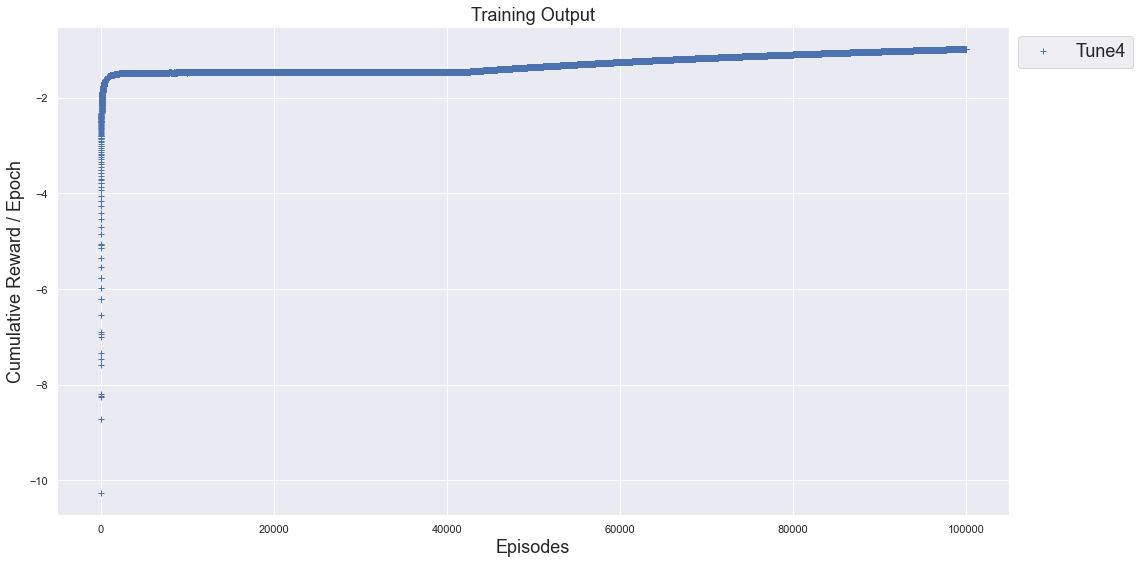

In [531]:
avgcumrewardsTune4=np.cumsum(np.array(all_rewards))/np.cumsum(np.array(all_epochs))
Tune4Output=pd.DataFrame(avgcumrewardsTune4)
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(Tune4Output[0],'+b',label ='Tune4')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Reward / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()

In [520]:
AllSearchResults2=pd.read_csv('AllSearchResults2.csv')
AllSearchResults2

,Base,Tune1,Tune2,Tune3,Tune4
0,-11.666667,-10.000000,-8.150000,-11.056338,-7.600000
1,-10.467626,-11.777778,-8.100000,-10.292398,-7.700000
2,-10.292887,-9.795918,-7.383333,-9.797048,-8.058036
3,-10.235988,-9.820225,-6.662500,-9.797844,-8.376866
4,-10.318907,-9.736434,-6.827309,-9.628450,-7.622283
...,...,...,...,...,...
99994,-1.253730,-1.392662,-0.957686,-1.303291,-0.806985
99995,-1.253741,-1.392653,-0.957678,-1.303281,-0.806984
99996,-1.253731,-1.392644,-0.957672,-1.303265,-0.806975
99997,-1.253721,-1.392636,-0.957663,-1.303253,-0.806967


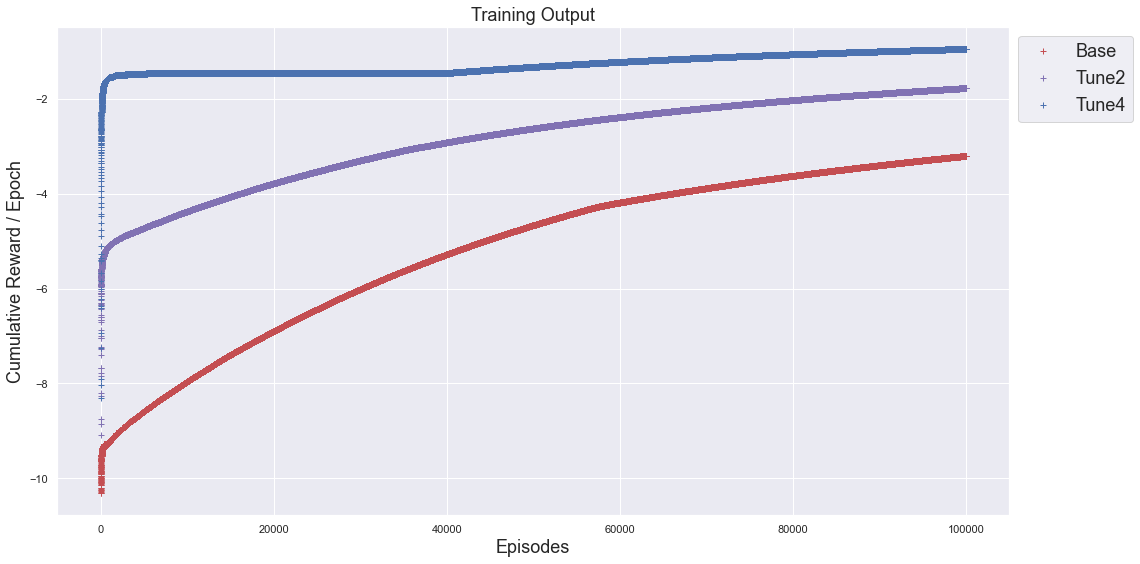

In [533]:
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(AllSearchResults['Base'],'+r',label ='Base')
ax1.plot(AllSearchResults['Tune2'],'+m',label ='Tune2')
ax1.plot(AllSearchResults['Tune4'],'+b',label ='Tune4')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Reward / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()

In [524]:
#Cumulative Reward by main action for best tuned model
avgcumrewardsPICKUP=np.cumsum(np.array(pickup_rewards))/np.cumsum(np.array(pickup_epochs))
PickupOutput=pd.DataFrame(avgcumrewardsPICKUP).rename(columns={0: 'Pickup'})
avgcumrewardsDROPOFF=np.cumsum(np.array(dropoff_rewards))/np.cumsum(np.array(dropoff_epochs))
DropoffOutput=pd.DataFrame(avgcumrewardsDROPOFF).rename(columns={0: 'DropOff'})
avgcumrewardsOPEN=np.cumsum(np.array(open_rewards))/np.cumsum(np.array(open_epochs))
OpenOutput=pd.DataFrame(avgcumrewardsOPEN).rename(columns={0: 'Open'})
ActionTable=PickupOutput.join(DropoffOutput).join(OpenOutput)
ActionTable=ActionTable.head(100)

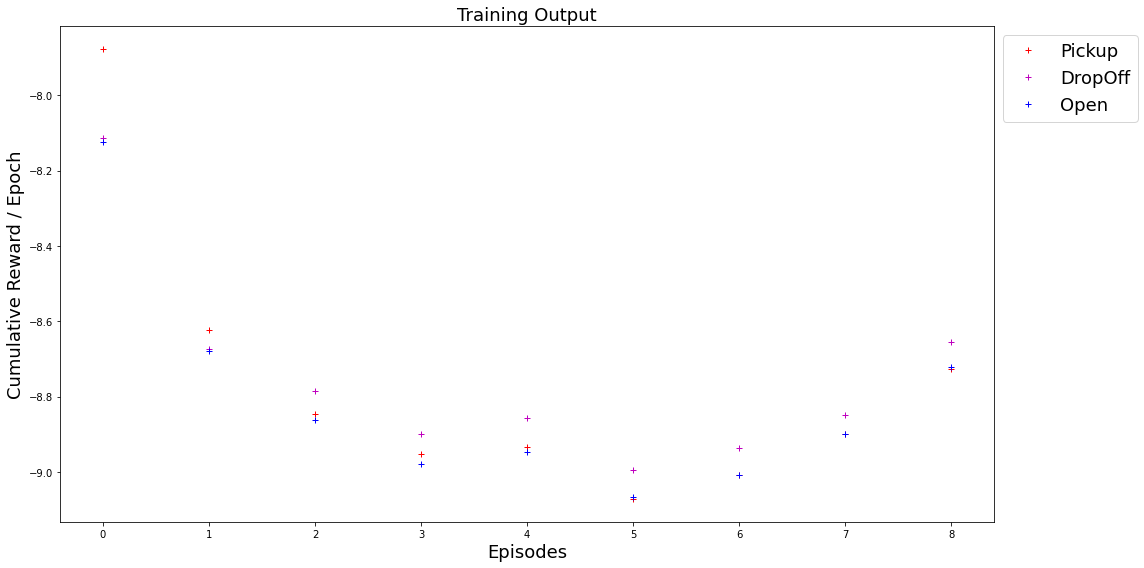

In [525]:
#It doesnt seem to gain more cumulative reward by episode but perhaps in first few episodes it would be clearer
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(ActionTable['Pickup'],'+r',label ='Pickup')
ax1.plot(ActionTable['DropOff'],'+m',label ='DropOff')
ax1.plot(ActionTable['Open'],'+b',label ='Open')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Reward / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()

In [534]:
#Cumulative Reward by main action for best tuned model
avgcumrewardsPICKUP=np.cumsum(np.array(pickup_rewards))/np.cumsum(np.array(pickup_epochs))
PickupOutput=pd.DataFrame(avgcumrewardsPICKUP).rename(columns={0: 'Pickup'})
avgcumrewardsDROPOFF=np.cumsum(np.array(dropoff_rewards))/np.cumsum(np.array(dropoff_epochs))
DropoffOutput=pd.DataFrame(avgcumrewardsDROPOFF).rename(columns={0: 'DropOff'})
avgcumrewardsOPEN=np.cumsum(np.array(open_rewards))/np.cumsum(np.array(open_epochs))
OpenOutput=pd.DataFrame(avgcumrewardsOPEN).rename(columns={0: 'Open'})
ActionTable=PickupOutput.join(DropoffOutput).join(OpenOutput)
ActionTable=ActionTable.head(10)

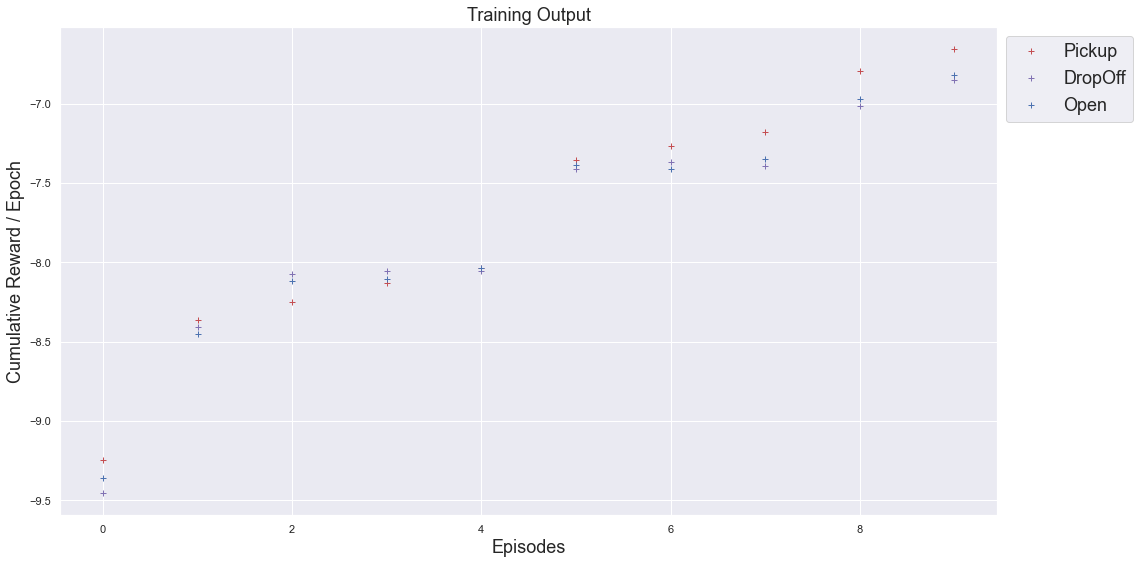

In [535]:
#It doesnt seem to gain more cumulative reward by episode but perhaps in first few episodes it would be clearer
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(ActionTable['Pickup'],'+r',label ='Pickup')
ax1.plot(ActionTable['DropOff'],'+m',label ='DropOff')
ax1.plot(ActionTable['Open'],'+b',label ='Open')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Reward / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()

In [519]:
#Cum Pickup
cumpickup=np.cumsum(np.array(pickup_epochs))
cumpickup=pd.DataFrame(cumpickup)
cumpickup['MA'] = 1
cumpickup['MACUM'] =np.cumsum(cumpickup['MA'])
cumpickup['PUCUMAVG']= cumpickup[0] / cumpickup['MACUM']
# Cum Drop Off
cumdropoff=np.cumsum(np.array(dropoff_epochs))
cumdropoff=pd.DataFrame(cumdropoff)
cumdropoff['MA'] = 1
cumdropoff['MACUM'] =np.cumsum(cumdropoff['MA'])
cumdropoff['DOCUMAVG']= cumdropoff[0] / cumdropoff['MACUM']
# Cum Open
cumopen=np.cumsum(np.array(open_epochs))
cumopen=pd.DataFrame(cumopen)
cumopen['MA'] = 1
cumopen['MACUM'] =np.cumsum(cumopen['MA'])
cumopen['OPCUMAVG']= cumopen[0] / cumopen['MACUM']
cumopen['test']=cumopen[0].diff().fillna(cumopen[0])
cumopen

,0,MA,MACUM,OPCUMAVG,test
0,192,1,1,192.000000,192.0
1,386,1,2,193.000000,194.0
2,404,1,3,134.666667,18.0
3,598,1,4,149.500000,194.0
4,675,1,5,135.000000,77.0
5,858,1,6,143.000000,183.0
6,1049,1,7,149.857143,191.0
7,1244,1,8,155.500000,195.0
8,1432,1,9,159.111111,188.0


In [518]:
cumopen

NameError: name 'cumopen' is not defined

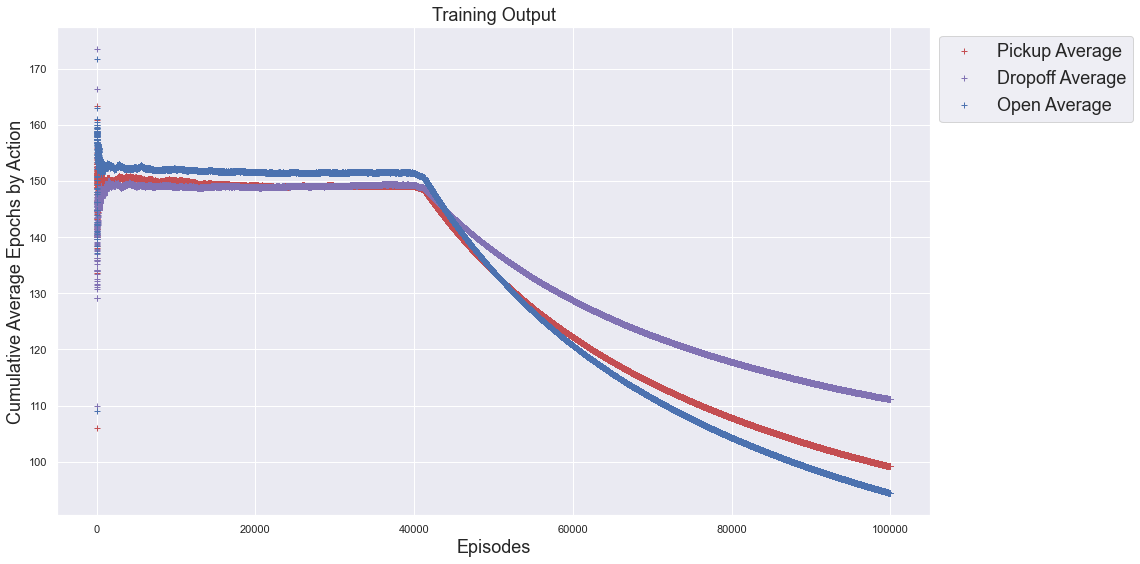

In [537]:
#Cumulative Epochs by Action
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(cumpickup['PUCUMAVG'].head(100000),'+r',label ='Pickup Average')
ax1.plot(cumdropoff['DOCUMAVG'].head(100000),'+m',label ='Dropoff Average')
ax1.plot(cumopen['OPCUMAVG'].head(100000),'+b',label ='Open Average')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Average Epochs by Action",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Training Output",fontsize=18)
plt.show()
#Essentially takes longer to figure out where to drop off as immediate rewards are more likely to come from picking up
#and opening doors?

In [466]:
Q

array([[  0.        ,   0.36034969,  -9.71172025, ..., -19.71172025,
        -19.71172025, -19.71172025],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       ...,
       [ 10.55691265,   0.        ,   0.        , ...,  -6.80385919,
        -86.80385919,  -6.80385919],
       [  0.        ,   0.        ,   0.        , ...,   0.        ,
          0.        ,   0.        ],
       [  0.61897002,   0.        ,   0.        , ..., -19.50482398,
        -99.50482398, -19.50482398]])

<AxesSubplot:>

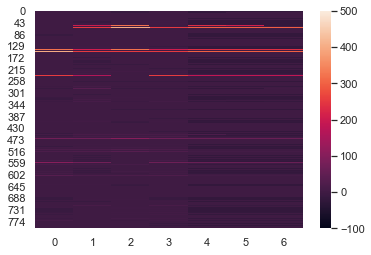

In [538]:
sns.heatmap(Q)

In [ ]:
Environment change

In [ ]:
env

# Evaluation

In [539]:
#action = np.argmax(Q[state]) # Exploit learned values
action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
for action,value in enumerate(Q[state]):
    if action in valid_actions:
        action_value[action] = value
action = np.random.choice(np.flatnonzero(action_value == action_value.max())) # Exploit learned values
#action = np.argmax(action_value) # Exploit learned values

next_state, reward, done, info = env.step(action) 
print(next_state, reward, done, info)

71 100 True {'prob': 1.0}


In [540]:
agent_row, agent_col, key_idx, host_idx, exit_idx = env.decode(152)
print(agent_row, agent_col, key_idx, host_idx, exit_idx)

agent_row, agent_col, key_idx, host_idx, exit_idx = env.decode(156)
print(agent_row, agent_col, key_idx, host_idx, exit_idx)


1 9 0 0 0
1 9 1 0 0


In [541]:
"""Evaluate agent's performance after Q-learning"""

total_epochs, total_penalties = 0, 0
episodes = 2

for _ in range(episodes):
    state = env.reset()
    epochs, penalties, reward = 0, 0, 0
    
    done = False
    #env.display()
    while not done:
        valid_actions = env.valid_actions()
        if not valid_actions: break
        action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
        for action,value in enumerate(Q[state]):
            if action in valid_actions:
                action_value[action] = value
        action = np.random.choice(np.flatnonzero(action_value == action_value.max())) # Exploit learned values
        
        state, reward, done, info = env.step(action)

        if epochs <200:
            print(env.time_elapsed,'-',env.s,'-',action_dict[action],'-',reward,'-',action)
            env.display()
        
        if reward < -1:
            penalties += 1

        
        epochs += 1

    total_penalties += penalties
    total_epochs += epochs

print(f"Results after {episodes} episodes:")
print(f"Average timesteps per episode: {total_epochs / episodes}")
print(f"Average penalties per episode: {total_penalties / episodes}")
print(f"Total penalties (Invalid pickups/dropoffs/open): {total_penalties}")

## What we noticed here is that the agent found a nice solution of picking up the key and escaping but if you cut
## the episodes too low it is only good at solving this more basic task not realising it needs to find a more convulted
## route and pick up the hostages and drop them off as wellfor the maximum reward. By about 25k it does this we have
##kept episodes at 40k as it runs in 5 minutes

1 - 688 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X A . . . 
. . . . . . . X H U 

2 - 768 - down - 0 - 1
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . A X H U 

3 - 760 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . A . X H U 

4 - 752 - left - 0 - 3
Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green)

67 - 743 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . A . . . . X H U 

68 - 735 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. A . . . . . X H U 

69 - 727 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (8, 7)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
A . . . . . . X H U 

70 - 647 - up - 0 - 0
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Gree

49 - 759 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (6, 9)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . A . . X H U 

50 - 751 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (6, 9)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . A . . . X H U 

51 - 743 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Green): 1 - Agent start (6, 9)
. X . . . . . . S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . A . . . . X H U 

52 - 735 - left - 0 - 3
Key (Yellow): 1 / Door (Blue): 1 / Hostage (Gr

## Environments change

In [8]:
import random

In [37]:
a = [random.uniform(.99,.7) for p in range(0, 10)] #0.7 to 0.99
a

[0.982483731503998,
 0.8893692435830687,
 0.7439242192661968,
 0.7697494328007762,
 0.9130113513878156,
 0.7438448336804906,
 0.9511292375429072,
 0.9346405605568329,
 0.9003129339107498,
 0.9337477944204973]

In [348]:
def epsilon_greedy_policy(env, epsilon, Q, state):
    valid_actions = env.valid_actions()
    # if there is an error with valid actions re run the step but there shouldnt be
    if not valid_actions: return -1
    # if a random number between 0 and 1 is less than our epsilon greedy value then Explore the space
    #print(Q[state])
    if random.uniform(0, 1) < epsilon: ################### HYPER PARAMETER ###################
        #Do this by taking a random choice of the list of valid actions at this step
        action = np.random.choice(valid_actions)
    else:
        #Otherwise set an action value array
        action_value = np.array([-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf,-np.inf])
        #For each action 0 to 6 in the Q matrix for a given state
        for action,value in enumerate(Q[state]):
            #If the action is a valid action for this step
            if action in valid_actions:
                #Then calculate action_value for taking that action, this value in the Q matrix is a.k.a expected reward
                action_value[action] = value
        #Once we know the expected rewards for all the valid actions we now take a greedy approach and 
        #Select the action which gives the maximum reward a.k.a Exploiting the learned values in the Q matrix
        action = np.random.choice(np.flatnonzero(action_value == action_value.max()))
        
    return action

In [401]:
# temp = Temperature function
def softmax_policy(env, temp, Q, state):
    valid_actions = env.valid_actions()
    # if there is an error with valid actions re run the step but there shouldnt be
    if not valid_actions: return -1
    p = np.array([Q[(state,x)]/temp for x in range(env.action_space)])
    prob_actions = np.exp(p) / np.sum(np.exp(p))
    cumulative_probability = 0.0
    choice = random.uniform(0,1)
    
    for action,pr in enumerate(prob_actions):
        cumulative_probability += pr
        if cumulative_probability > choice and action in valid_actions:
            return action

In [408]:
%%time
"""Training the agent"""

"""Grid Search Parameters:""

Alpha Values: 0.9,0.1
Gamma Values: 0.8,0.5
Epsilon Values: 0.9,0.5

"""
from IPython.display import clear_output

def QLearning (env,num_episodes,lr,discount_factors,
               epsilon,epsilon_decay,display_mode,policy,temp):
    # Variables
    N = 10
    M = 10
    episodes = num_episodes #100000
    stats_frequency = 50
    
    # Hyperparameters
    alpha = lr #0.9 #0.1 or 0.9
    gamma = discount_factors # discount_factors #0.8 #0.5 or 0.8

    # Exploration rate.
    epsilon = epsilon #epsilon #0.5 #0.5 ot 0.9

    # Exploration decay rate.
    DECAY_RATE = epsilon_decay #epsilon_decay #0.95 #0.9998          

    # For plotting metrics and saving stats
    all_epochs = []
    all_rewards = []
    dropoff_epochs = []
    dropoff_rewards = []
    pickup_epochs = []
    pickup_rewards = []
    open_epochs = []
    open_rewards = []
    state_count1000f =[]
    state_count1000l =[]
    
    ep_rewards = []
    aggr_ep_rewards = {'ep': [], 'avg': [], 'max': [], 'min': []}


    Q = np.zeros([env.observation_space, env.action_space])

    for i in range(1, episodes):
        #reset the environment start of each episode being looped and randomly allocate agent
        state = env.reset()
        #reset the epoch steps to 0 and rewards to 0
        epochs, reward, cumreward, epochs_pickup, cumreward_pickup, epochs_dropoff, cumreward_dropoff, epochs_open, cumreward_open  = 0, 0, 0, 0, 0, 0, 0, 0, 0
        #reset terminal status to false
        done = False
        #reset number of epoch steps taken to terminal status to 0
        exit_num_steps = 0

        #while in new episode and not a terminal state 
        while not done:
            #define the valid actions that are allowed from the map walking environment
            if policy == 'epsilon_greedy' or policy == 'epsilon_greedy_decay':
                action = epsilon_greedy_policy(env, epsilon, Q, state)
            elif policy == 'softmax':
                action = softmax_policy(env, temp, Q, state)
            else:
                break
            
            #Once we have selected an action we take it and observe the instant reward if there is one and the next state position
            next_state, reward, done, info = env.step(action) 

            ## Update the Q value ##

            #save existing value
            old_value = Q[state, action]
            #figure out what the maximum action value is from the next state, which could be better than what we arleady expected
            next_max = np.max(Q[next_state])
            # update the current state action pair using the q learning update rule which utilises the knowledge of the next state
            # which may have exploited prior knowledge or have gone in a random direction and learnt something new, which in turn
            # may have updated the current state expected reward if a higher reward was available going in the random direction
            #this in turn will allow better exploitation in the next episode as the algorithm learns the best states and actions to take
            new_value = old_value + alpha * ((reward + gamma * next_max) - old_value) ###### HYPER PARAMETERS ########
            Q[state, action] = new_value

            #calculate number of steps taken in the episode before exit
            if env.exit_steps == 1:
                exit_num_steps  = epochs  

            #pickup
            if action == 4:
                epochs_pickup = epochs
                cumreward_pickup = cumreward

            #dropoff
            if action == 5:
                epochs_dropoff = epochs
                cumreward_dropoff = cumreward

            #open
            if action == 6:
                epochs_open = epochs
                cumreward_open = cumreward

            # go to the next state
            state = next_state

            #update the cumulative epochs and rewards
            epochs += 1
            cumreward += reward
            ep_rewards.append(reward)

        # if epsilon is > 0.15 then keep decaying otherwise just keep it at 0.15 to always maintain some exploration
        # this is because the state action space is quite large and want to ensure as many actions are taken as possible
        if policy == 'epsilon_greedy_decay':
            if epsilon > 0.05:
                epsilon *= DECAY_RATE                 # Decaying the exploration rate every episode.
            else:
                epsilon = 0.05

        all_epochs.append(epochs)
        all_rewards.append(cumreward)
        pickup_epochs.append(epochs_pickup)
        pickup_rewards.append(cumreward_pickup)
        dropoff_epochs.append(epochs_dropoff)
        dropoff_rewards.append(cumreward_dropoff)
        open_epochs.append(epochs_open)
        open_rewards.append(cumreward_open)

        if i < 1001:
            state1000f=state
            state_count1000f.append(state1000f)

        if i > (episodes-1000):
            state1000l=state
            state_count1000l.append(state1000l)

        #outputs visual of the environment at every X episodes shwoing where the agent is
        if i % 100 == 0 and display_mode == True:
            clear_output(wait=True)
            print(f"Episode: {i}")
            env.display()
            print('Time Elapsed:',env.time_elapsed,'-','State:',env.s,'-','Action:',action_dict[action],'-','Reward:',reward,
            print('Steps to open door:',exit_num_steps, '-','Steps to complete:',exit_num_steps))
        
        #if i % 1000 == 0:
            #print(i)
        
        if i % stats_frequency == 0:
            average_reward = sum(ep_rewards[-stats_frequency:])/stats_frequency
            aggr_ep_rewards['ep'].append(i)
            aggr_ep_rewards['avg'].append(average_reward)
            aggr_ep_rewards['max'].append(max(ep_rewards[-stats_frequency:]))
            aggr_ep_rewards['min'].append(min(ep_rewards[-stats_frequency:])) 

    
    print("Training finished.\n")
    return all_epochs, all_rewards, aggr_ep_rewards, pickup_epochs, \
           pickup_rewards, dropoff_epochs, dropoff_rewards, open_epochs, open_rewards 

Wall time: 0 ns


In [431]:
np.zeros((10, 10), dtype=np.float64)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [473]:
def hyper_param_change(env, num_episodes, param_grid):
    lrs = [round(random.uniform(1e-4,1e-2),4) for p in range(0, param_grid)] #0.0001 to 0.01
    discount_factors = [round(random.uniform(.95,.8),2) for p in range(0, param_grid)] #0.7 to 0.99
    epsilons = [round(random.uniform(.99,.7),2) for p in range(0, param_grid)] #0.7 to 0.999
    epsilon_decays = [round(random.uniform(.999,.99),4) for p in range(0, param_grid)] #0.9 to 0.999
    #nbatch_sizes = [randrange(64,512) for p in range(0, 10)]
    #optimizers = ['adam', 'adagrad', 'adadelta', 'sgd', 'rmsprop']

#     num_epochs=100, max_timesteps=128, epsilon_start=1, 
#                                              epsilon_end=0.1, epsilon_decay=0.9994, qtarget_update=1000,
#                                              fc1_dim=75, fc2_dim=50,learning_rate=0.001, gamma=0.9,
#                                              loss_fun='mse',conv=False,dueling=False,ddqn=True,per=True
    
    i_model = 0
    lr_ = []
    discount_factors_ = []
    epsilon_ = []
    epsilon_decay_ = []
    
    num_episodes_50 = round(num_episodes/50) - 1
    
    all_epochs_ = np.zeros((param_grid, num_episodes-1), np.float64)
    all_rewards_ = np.zeros((param_grid, num_episodes-1), np.float64)
    aggr_ep_rewards_ep_ = np.zeros((param_grid, num_episodes_50), np.float64)
    aggr_ep_rewards_max_ = np.zeros((param_grid, num_episodes_50), np.float64)
    aggr_ep_rewards_min_ = np.zeros((param_grid, num_episodes_50), np.float64)
    aggr_ep_rewards_avg_ = np.zeros((param_grid, num_episodes_50), np.float64)
    pickup_epochs_ = np.zeros((param_grid, num_episodes-1), np.float64)
    pickup_rewards_ = np.zeros((param_grid, num_episodes-1), np.float64)
    dropoff_epochs_ = np.zeros((param_grid, num_episodes-1), np.float64)
    dropoff_rewards_ = np.zeros((param_grid, num_episodes-1), np.float64) 
    open_epochs_ = np.zeros((param_grid, num_episodes-1), np.float64)
    open_rewards_ = np.zeros((param_grid, num_episodes-1), np.float64)
    
    i_model = 0
    
    for lr, discount_factor, epsilon, epsilon_decay in zip(lrs, discount_factors, epsilons, epsilon_decays):
    #optimizer = random.choice(optimizers)
        #args = hyper_param(lr)
        # pass args into the main function 
        #print(args)
        all_epochs, all_rewards, aggr_ep_rewards, pickup_epochs, pickup_rewards, \
           dropoff_epochs, dropoff_rewards, open_epochs, open_rewards = \
           QLearning(env,num_episodes,lr,discount_factor,
                     epsilon,epsilon_decay,display_mode=False,policy='epsilon_greedy_decay',temp=0)
        
        lr_.append(lr)
        discount_factors_.append(discount_factor)
        epsilon_.append(epsilon)
        epsilon_decay_.append(epsilon_decay)
        
        all_epochs_[i_model] = all_epochs
        all_rewards_[i_model] = all_rewards
        #print(aggr_ep_rewards['max'])
        aggr_ep_rewards_ep_[i_model] = aggr_ep_rewards['ep']
        aggr_ep_rewards_max_[i_model] = aggr_ep_rewards['max']
        aggr_ep_rewards_min_[i_model] = aggr_ep_rewards['min']
        aggr_ep_rewards_avg_[i_model] = aggr_ep_rewards['avg']
        
        pickup_epochs_[i_model] = pickup_epochs
        pickup_rewards_[i_model] = pickup_rewards
        dropoff_epochs_[i_model] = dropoff_epochs
        dropoff_rewards_[i_model] = dropoff_rewards
        open_epochs_[i_model] = open_epochs
        open_rewards_[i_model] = open_rewards
        
        i_model += 1
        
#         all_epochs_.append(all_epochs)
#         all_rewards_.append(all_rewards)
#         aggr_ep_rewards_.append(aggr_ep_rewards)
#         pickup_epochs_.append(pickup_epochs)
#         pickup_rewards_.append(pickup_rewards_)
#         dropoff_epochs_.append(dropoff_epochs)
#         dropoff_rewards_.append(dropoff_rewards)
#         open_epochs_.append(open_epochs)
#         open_rewards_.append(open_rewards)
 

    return all_epochs_, all_rewards_, aggr_ep_rewards_ep_, aggr_ep_rewards_max_, aggr_ep_rewards_min_, \
           aggr_ep_rewards_avg_, pickup_epochs_, pickup_rewards_,  dropoff_epochs_, dropoff_rewards_, \
           open_epochs_, open_rewards_, lr_, discount_factors_, epsilon_, epsilon_decay_
    


## Environment 1

In [412]:
# Load environment class
from environment_door_reward import MapWalkingEnvDoorReward

In [415]:
env = MapWalkingEnvDoorReward(10,10)

In [487]:
all_epochs_e1, all_rewards_e1, aggr_ep_rewards_ep_e1, aggr_ep_rewards_max_e1, aggr_ep_rewards_min_e1, \
aggr_ep_rewards_avg_e1, pickup_epochs_e1, pickup_rewards_e1, dropoff_epochs_e1, dropoff_rewards_e1, \
open_epochs_e1, open_rewards_e1, lr_e1, discount_factors_e1, epsilon_e1, epsilon_decay_e1 = hyper_param_change(env,30000,8)

Training finished.

Training finished.

Training finished.

Training finished.

Training finished.

Training finished.

Training finished.

Training finished.



In [477]:
aggr_ep_rewards_ep_e1[0]

array([ 50., 100., 150., 200., 250.])

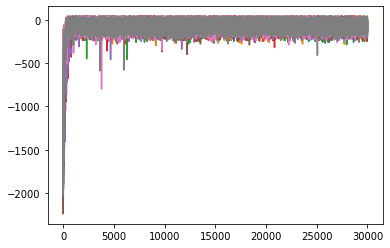

In [488]:
episodes = np.arange(len(all_rewards_e1[0]))

plt.plot(episodes, all_rewards_e1[0], label = "Experiment 1", linestyle="-")
plt.plot(episodes, all_rewards_e1[1], label = "Experiment 2", linestyle="-")
plt.plot(episodes, all_rewards_e1[2], label = "Experiment 3", linestyle="-")
plt.plot(episodes, all_rewards_e1[3], label = "Experiment 4", linestyle="-")
plt.plot(episodes, all_rewards_e1[4], label = "Experiment 5", linestyle="-")
plt.plot(episodes, all_rewards_e1[5], label = "Experiment 6", linestyle="-")
plt.plot(episodes, all_rewards_e1[6], label = "Experiment 7", linestyle="-")
plt.plot(episodes, all_rewards_e1[7], label = "Experiment 8", linestyle="-")
#plt.plot(all_epochs_[1], all_rewards_e1[1], label = "line 2", linestyle="--")

In [438]:
aggr_ep_rewards

{'ep': [100, 200, 300, 400, 500, 600, 700, 800, 900],
 'avg': [-10.2, -10.9, -9.7, -9.5, -9.3, -8.6, -10.9, -9.0, -7.6],
 'max': [20, 0, 0, 0, 0, 0, 0, 0, 0],
 'min': [-20, -20, -20, -100, -100, -100, -100, -20, -20]}

In [428]:
len(all_rewards)

999

In [298]:
pd.DataFrame([lr_,discount_factors_, epsilon_, epsilon_decay_]).transpose()

#lr_,discount_factors_, epsilon_, epsilon_decay_])

,0,1,2,3
0,0.00477383,0.774639,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
1,0.00950297,0.846111,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
2,0.00111332,0.804252,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
3,0.00609794,0.957714,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
4,0.00377763,0.834983,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
5,0.00352781,0.75363,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
6,0.00791299,0.840113,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
7,0.00388408,0.787306,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
8,0.00318928,0.980515,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."
9,0.00258976,0.918273,"[0.8147060966836243, 0.870118836706427, 0.9635...","[0.9941485584506894, 0.9962140277026328, 0.992..."


## Experiment 2

In [497]:
# Load environment class
from environment_hostage_pos_update import MapWalkingEnvHostageUpdate

ImportError: cannot import name 'MapWalkingEnvHostageUpdate' from 'environment_hostage_pos_update' (C:\MSc\Modules\Deep Reinforcement Learning\Coursework\environment_hostage_pos_update.py)

In [493]:
import numpy as np
from discrete_space import Discrete

#These are the key actions you can apply at states
action_dict = {
    0: 'up',
    1: 'down',
    2: 'right',
    3: 'left',
    4: 'pickup',
    5: 'dropoff',
    6: 'open'
}

#Colours for environment
color2num = dict(
    gray=30,
    red=31,
    green=32,
    yellow=33,
    blue=34,
    magenta=35,
    cyan=36,
    white=37,
    crimson=38,
)

#Function to surround string with certain colour codes
def colorise(string, color, bold=False, highlight=False):
    attr = []
    num = color2num[color]
    if highlight:
        num += 10
    attr.append(str(num))
    if bold:
        attr.append("1")
    attrs = ";".join(attr)
    return f"\x1b[{attrs}m{string}\x1b[0m"

# A function that counts the number of true values when the cumulative sum of n probabilities
#In an array is greater than a randomly generated number used in the step function



class MapWalkingEnvHostagePosUpdate:

    def __init__(self, N, M):
        # Numpy array that holds the information about the environment
        self.territory = np.zeros((N, M), dtype = np.int8)
        self.height = N
        self.width = M
        self.size = N * M 
        self.average_size = round((N+M)/2,0)
        self.hostage = 1 # 1 hostage zones
        self.exit = 2 # 1 safe zone and 1 unsafe
        
        # Number of random objects
        self.number_keys = 1
        self.number_hostages = 1
        self.number_mines = 1
        self.exit_steps = None 

        # Define Walls (Static coordinates)
        wall_states = [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)]
        
        for i,j in wall_states:
            self.territory[i,j] = 1
        
        # Pick coordinates for the mine
        self.mine_coord = mine_coord = (0,9) # Static coordinates
        self.territory[mine_coord[0], mine_coord[1]] = 2

        # Pick 2 random coordinates to the safe zone and unsafe zone respectively
        #self.exit_coord = exit_coord = self.get_exit_cells(self.exit) # Dynamic coordinates
        self.exit_coord = exit_coord = ((0,8),(9,9))  # Static coordinates
        self.territory[exit_coord[0][0], exit_coord[0][1]] = 5 # Safe
        self.territory[exit_coord[1][0], exit_coord[1][1]] = 6 # Unsafe
        
        # Pick 1 random coordinate for the key
        #self.key_coord = key_coord = self.get_empty_cells(self.number_keys) # Dynamic coordinates
        self.key_coord = key_coord = (5,7) # Static coordinates
        self.territory[key_coord[0],key_coord[1]] = 3
         
        # Pick 1 random coordinate for the hostage zone
        #self.hostage_coord = hostage_coord = self.get_empty_cells(self.number_hostages) # Dynamic coordinates
        self.hostage_coord = hostage_coord = (0,7) # Static coordinates
        self.territory[hostage_coord[0],hostage_coord[1]] = 4
        
        self.displ_board = np.zeros((8, 10, 10), dtype=np.uint8)
        self.add_encoded_states()
        
        # initial position of the agent will be decided by resetting the environment.
        self.position_agent = None
        self.start_agent = None

        # run time
        self.time_elapsed = 0
        self.time_limit = 2*self.size #* 8

        # display help
        self.dict_map_display={ 0:'.', #0 : empty cell
                                1:'X', #1 : walls obstacle that are non-traversable
                                2:'M', #2 : mine field location
                                3:'K', #3 : key location
                                4:'H', #3 : hostage zone    
                                5:'S', #4 : safe zone
                                6:'U', #6 : unsafe zone
                                7:'A'  #7 : agent location
                              }
       

        num_states = self.size * 8
        num_rows = N
        num_columns = M
        max_row = num_rows - 1
        max_col = num_columns - 1
        self.initial_state_distrib = np.zeros(num_states)
        num_actions = 7
        
        # Set available actions
        self.actions = [0,1,2,3,4,5,6]
    
        #self.actions = ['up','down','left','right','pickup','dropoff','open']
        
        self.P = {
            state: {action: [] for action in range(num_actions)}
            for state in range(num_states)
        }
        self.states_array = {
            state   : {}
            for state in range(num_states)
        }
        self.observations_array = {
            state   : {}
            for state in range(num_states)
        }
        
        # Create matrix of possible transitions, essentially like R matrix
        for row in range(num_rows): #7
            for col in range(num_columns): #7
                for key_idx in range(2): # +1 for key being with agent
                    for host_idx in range(2): # +1 for host being with agent
                        for exit_idx in range(2): # for tracking if door was opened or not
                            state = self.encode(row, col, key_idx, host_idx, exit_idx)

                            if  (self.territory[row, col] != 1) \
                                and self.territory[row, col] != 2 \
                                and (key_idx < 1 and host_idx < 1 and exit_idx < 1):
                                self.initial_state_distrib[state] += 1
                                self.states_array[state] = (row, col)
                            if  self.territory[row, col] != 1: 
                                self.observations_array[state] = (row, col)
                            
                            valid_actions = self.valid_actions(row, col)
                            
                            for action in valid_actions:
                                # defaults
                                new_row, new_col, new_key_idx, new_host_idx, new_exit_idx=row, col, key_idx, host_idx, exit_idx
                                reward = (
                                    0 #-0.1
                                )  # Default reward when there is no pickup/dropoff/open and agent moves to an open cell (not a wall or a mine)
                                
                                done = False
                                agent_loc = (row, col)
                                

                                if action == 0: #'up' 
                                    new_row = max(row - 1, 0)
                                elif action == 1: #'down' 
                                    new_row = min(row + 1, max_row)
                                elif action == 2: #'right' 
                                    new_col = min(col + 1, max_col)
                                elif action == 3: #'left':
                                    new_col = max(col - 1, 0)
                                elif action == 4: #'pickup' 
                                    if new_host_idx == 0 and new_key_idx == 1 and new_exit_idx == 1 and \
                                    (agent_loc == (hostage_coord[0],hostage_coord[1])):
                                        new_host_idx = 1
                                        #reward = 20
                                    elif new_key_idx == 0 and (agent_loc == (key_coord[0],key_coord[1])):
                                        new_key_idx = 1
                                        reward = 20
                                    elif self.territory[new_row, new_col] != 2: # key not at location or agent did not open a door yet and receives a negative rewards
                                        reward = -20
                                elif action == 5: #'dropoff' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1]) and \
                                        new_key_idx == 1 and new_host_idx == 1): # desired terminal state
                                        done = True
                                        reward = 100
                                    elif agent_loc == (exit_coord[1][0],exit_coord[1][1]) : # undesired terminal state
                                        done = True
                                        reward = -100
                                    elif self.territory[new_row, new_col] != 2:  # dropoff at wrong location and receives a negative rewards
                                        reward = -20
                                elif action == 6: #'open' 
                                    if (agent_loc == (exit_coord[0][0],exit_coord[0][1])) and (new_key_idx == 1 and new_exit_idx == 0):
                                        new_exit_idx = 1
                                        reward = 20
                                    elif self.territory[new_row, new_col] != 2:  # open at wrong location and receives a negative rewards
                                        reward = -20

                                if (new_host_idx == 1 and new_key_idx == 1) or \
                                    new_exit_idx == 1:
                                    new_exit_idx=1
                                else:
                                    new_exit_idx=0
                                    
                                # If the agent bumps into a wall, it doesn't move and receives a negative rewards
                                if self.territory[new_row, new_col] == 1:
                                    new_row = row
                                    new_col = col
                                    reward = -10
                                
                                # If the agent bumps into a mine it reaches a terminal state and receives a negative rewards
                                if self.territory[new_row, new_col] == 2:
                                    new_row = row
                                    new_col = col
                                    done = True
                                    reward = -100 

                                if self.territory[row, col] != 1 and self.territory[row, col] != 2:
                                    new_state = self.encode(
                                        new_row, new_col, new_key_idx, new_host_idx, new_exit_idx
                                    )
                                    
                                    self.P[state][action].append((1.0, new_state, reward, done))
                       
        self.initial_state_distrib /= self.initial_state_distrib.sum()
        self.action_space = Discrete(num_actions) #int(num_actions)
        self.observation_space = Discrete(num_states) # Encoded states shape
        self.observation_space_decoded = len(list(self.decode_grid(0))) # Decoded states shape

    def get_empty_cells(self, n_cells):
        empty_cells_coord = np.where( self.territory == 0 )
        selected_indices = np.random.choice( np.arange(len(empty_cells_coord[0])), n_cells )
        selected_coordinates = empty_cells_coord[0][selected_indices], empty_cells_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates
    
    def add_encoded_states(self):
        wall_states = [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)]
    
        components = {'wall': [(0,1),(1,5),(2,5),(3,0),(3,1),(3,3),(3,4),(3,6),(4,2),(4,4),(4,6),(4,7),(4,8),
                       (5,2),(5,4),(7,6),(7,7),(7,8),(7,9),(8,1),(8,2),(8,3),(8,4),(8,5),(9,7)],
                      'mine': [(0,9)],
                      'safe':[(0,8)],
                      'unsafe':[(9,9)],
                      'key':[(5,7)],
                      'door':[(0,8)],
                      'hostage':[(9,8)]}
    
        #components['agent'] = [(4,5)]
        layer = 0
        for name, piece in components.items():
            #pos = (layer,) + piece.pos
            for index in piece:
                self.displ_board[layer][index] = 1
            layer += 1

    def decode_grid(self, state):
        
        row, col, key_idx, host_idx, exit_idx = np.array([v for _,v in enumerate(self.decode(state))])
        
        # Reset agent 
        layer = 7
        self.displ_board[layer][:] = 0
        
        # Move agent to new location
        self.displ_board[7][row, col] = 1
        
        # If key is found
        if (key_idx == 1):
            layer = 4
            self.displ_board[layer][:] = 0
            # Update key location with agent location
            self.displ_board[4][row, col] = self.displ_board[7][row, col]
        
        # If door is found
        if (exit_idx == 1):
            layer = 5
            self.displ_board[layer][:] = 0
            # Update door location with agent location
            self.displ_board[5][row, col] = self.displ_board[7][row, col]
        
        # If hostage is found
        if (host_idx == 1):
            layer = 6
            self.displ_board[layer][:] = 0
            # Update hostage location with agent location
            self.displ_board[6][row, col] = displ_board[7][row, col]

        return self.displ_board.reshape(-1)


    def get_exit_cells(self, n_cells):
        y=np.arange(self.territory.shape[0] * self.territory.shape[1]).reshape(self.territory.shape[0], self.territory.shape[1])        
        border_coord_indices = list(np.unique(np.array(sorted(np.concatenate([y[0,:],y[-1,:],y[:,0], y[:,-1]]))).reshape(1,-1)))
        border_coord=np.zeros((2,len(border_coord_indices)),dtype = np.int8)
        border_coord[0] = [int(i) for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]
        border_coord[1] = [j for i,ival in enumerate(y) for j,jval in enumerate(ival) if y[i,j] in border_coord_indices]

        selected_indices = np.random.choice( np.arange(len(border_coord[0])), n_cells )
        selected_coordinates = border_coord[0][selected_indices], border_coord[1][selected_indices]
        
        if n_cells == 1:
            return np.asarray(selected_coordinates).reshape(2,)
        
        return selected_coordinates

    
    # a key function for the q learning update rule
    def step(self, action):
        transitions = self.P[self.s][action]
        i = self.categorical_sample([t[0] for t in transitions], np.random)
        p, state, reward, done = transitions[i]
        self.s = state
        self.lastaction = action
        
        if done == False:
            self.position_agent = (self.observations_array[self.s][0],self.observations_array[self.s][1])

        # Update time elapsed
        self.time_elapsed+=1
        
        _, _, _, _, self.exit_steps = self.decode(self.s)

        if self.time_elapsed == self.time_limit:
            done = True
        
        return (int(state), reward, done, {"prob": p})
   

    def eval_reward(self):
        if (self.position_agent == (self.exit_coord[1][0], self.exit_coord[1][1]) or \
           (self.position_agent == (self.mine_coord[0][0], self.mine_coord[0][1]))):
            return -100
        elif (self.position_agent == (self.exit_coord[0][0], self.exit_coord[0][1])):
            return 100
        else:
            return -1
    
    
    def encode(self, agent_row, agent_col, key_idx, host_idx, exit_idx):
        i = agent_row
        i *= 10
        i += agent_col
        i *= 2
        i += key_idx
        i *= 2
        i += host_idx
        i *= 2
        i += exit_idx
        return i

    def decode(self, i):
        out = []
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 2)
        i = i // 2
        out.append(i % 10)
        i = i // 10
        out.append(i)
        assert 0 <= i < 10
        return reversed(out)
    
    def categorical_sample(self, prob_n, np_random):
        prob_n = np.asarray(prob_n)
        csprob_n = np.cumsum(prob_n)
        return (csprob_n > np_random.random()).argmax()
    
    def display(self, mode='human'):
 
        envir_with_agent = self.territory.copy()
        envir_with_agent[self.position_agent[0], self.position_agent[1]] = 7
        
        agent_row, agent_col, key_idx, host_idx, exit_idx = self.decode(self.s)

        full_repr = ""

        for r in range(self.height):
            
            line = ""
            
            for c in range(self.width):
                
                string_repr = self.dict_map_display[ envir_with_agent[r,c] ]
                line += "{0:2}".format(string_repr)

            full_repr += line + "\n"
        
        if key_idx == 1 and exit_idx == 0: # Agent found the key but did not open the door yet
            full_repr = full_repr.replace('A',colorise('A', "yellow", highlight=True))
        elif exit_idx == 1 and host_idx == 0: # Agent opened the door but did not find hostage
            full_repr = full_repr.replace('A',colorise('A', "blue", highlight=True))
        elif host_idx == 1: # Agent found the hostage
            full_repr = full_repr.replace('A',colorise('A', "green", highlight=True))

        print('Key (Yellow):',key_idx,'/ Door (Blue):',exit_idx,'/ Hostage (Green):',host_idx,'- Agent start',self.start_agent)
        print(full_repr)

        
    def reset(self, return_info: bool = False):
        #This function resets the environment for the agent
        self.time_elapsed = 0
         
        invalid_position = True                                    


        while invalid_position == True:
            self.s = self.categorical_sample(self.initial_state_distrib, np.random)
            new_coord = self.states_array[self.s]
            #print(new_coord)
            if      ((new_coord[0],new_coord[1]) != (self.exit_coord[0][0],self.exit_coord[0][1])) \
                and ((new_coord[0],new_coord[1]) != (self.exit_coord[1][0],self.exit_coord[1][1])) \
                and ((new_coord[0],new_coord[1]) != (self.hostage_coord[0],self.hostage_coord[1])) \
                and ((new_coord[0],new_coord[1]) != (self.key_coord[0],self.key_coord[1])):
                invalid_position = False
                self.position_agent = (new_coord[0],new_coord[1])
        
        #self.position_agent = (6,9)
        # Assign position to agent
        self.start_agent = self.position_agent
        
        # Move agent to new location
        self.displ_board[7][new_coord[0],new_coord[1]] = 1
        
        self.lastaction = None
        if not return_info:
            return int(self.s)
        else:
            return int(self.s), {"prob": 1}
        #return observations
        
        
    def valid_actions(self, row=None, col=None, cell=None):
        actions = [0, 1, 2, 3, 4, 5, 6]
        if (row == None and col == None):
            row = self.observations_array[self.s][0]
            col = self.observations_array[self.s][1]

        nrows, ncols = self.territory.shape
        if row == 0:
            actions.remove(0)
        elif row == nrows-1:
            actions.remove(1)

        if col == 0:
            actions.remove(3)
        elif col == ncols-1:
            actions.remove(2)
            
        return actions

In [492]:
env = MapWalkingEnvHostagePosUpdate(10,10)

NameError: name 'MapWalkingEnvHostagePosUpdate' is not defined

In [ ]:
all_epochs_e2, all_rewards_e2, aggr_ep_rewards_ep_e2, aggr_ep_rewards_max_e2, aggr_ep_rewards_min_e2, \
aggr_ep_rewards_avg_e2, pickup_epochs_e2, pickup_rewards_e2, dropoff_epochs_e2, dropoff_rewards_e2, \
open_epochs_e2, open_rewards_e2, lr_e2, discount_factors_e2, epsilon_e2, epsilon_decay_e2 = hyper_param_change(env,30000,8)

In [528]:
# Load pickle files to repeat the experiments for Environments 1 and 2  
import pickle
with open('experiment1_gridsearch.pickle','rb') as f:   
    all_epochs_e1, all_rewards_e1, aggr_ep_rewards_ep_e1, aggr_ep_rewards_max_e1, aggr_ep_rewards_min_e1, \
    aggr_ep_rewards_avg_e1, pickup_epochs_e1, pickup_rewards_e1, dropoff_epochs_e1, dropoff_rewards_e1, \
    open_epochs_e1, open_rewards_e1, lr_e1, discount_factors_e1, epsilon_e1, epsilon_decay_e1 = pickle.load(f)

with open('experiment2_gridsearch.pickle','rb') as f:   
    all_epochs_e2, all_rewards_e2, aggr_ep_rewards_ep_e2, aggr_ep_rewards_max_e2, aggr_ep_rewards_min_e2, \
    aggr_ep_rewards_avg_e2, pickup_epochs_e2, pickup_rewards_e2, dropoff_epochs_e2, dropoff_rewards_e2, \
    open_epochs_e2, open_rewards_e2, lr_e2, discount_factors_e2, epsilon_e2, epsilon_decay_e2 = pickle.load(f)

with open('experiment1_best_param.pickle','rb') as f: 
    all_epochs_e1_f, all_rewards_e1_f, aggr_ep_rewards_e1_f, pickup_epochs_e1_f, pickup_rewards_e1_f, \
    dropoff_epochs_e1_f, dropoff_rewards_e1_f, open_epochs_e1_f, open_rewards_e1_f  = pickle.load(f)

with open('experiment2_best_param.pickle','rb') as f:  
    all_epochs_e2_f, all_rewards_e2_f, aggr_ep_rewards_e2_f, pickup_epochs_e2_f, pickup_rewards_e2_f, \
    dropoff_epochs_e2_f, dropoff_rewards_e2_f, open_epochs_e2_f, open_rewards_e2_f  = pickle.load(f)


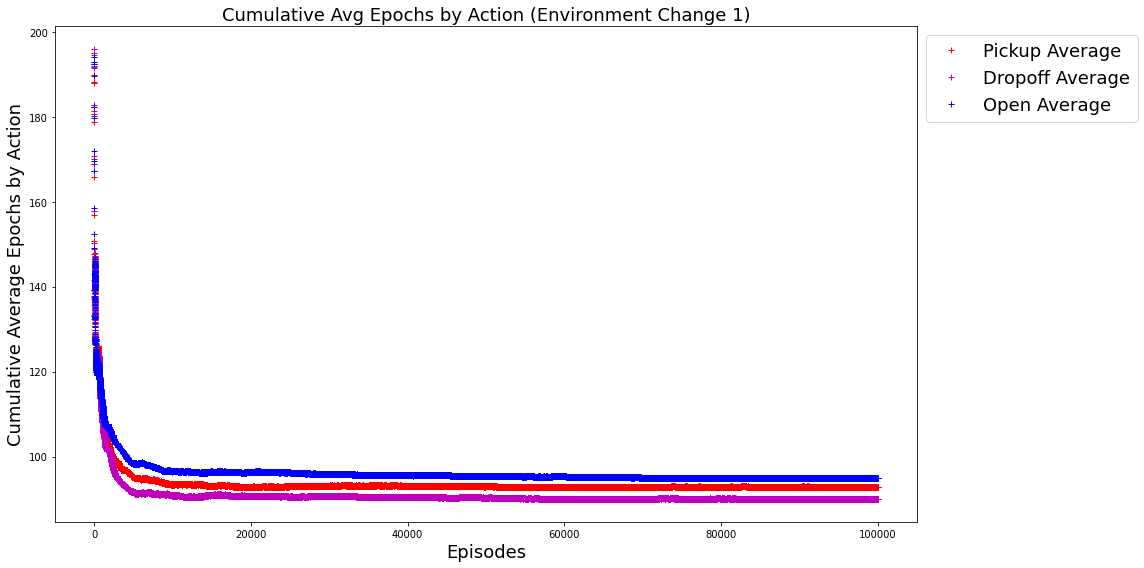

In [531]:
#Cum Pickup
cumpickup=np.cumsum(np.array(pickup_epochs_e1_f))
cumpickup=pd.DataFrame(cumpickup)
cumpickup['MA'] = 1
cumpickup['MACUM'] =np.cumsum(cumpickup['MA'])
cumpickup['PUCUMAVG']= cumpickup[0] / cumpickup['MACUM']
# Cum Drop Off
cumdropoff=np.cumsum(np.array(dropoff_epochs_e1_f))
cumdropoff=pd.DataFrame(cumdropoff)
cumdropoff['MA'] = 1
cumdropoff['MACUM'] =np.cumsum(cumdropoff['MA'])
cumdropoff['DOCUMAVG']= cumdropoff[0] / cumdropoff['MACUM']
# Cum Open
cumopen=np.cumsum(np.array(open_epochs_e1_f))
cumopen=pd.DataFrame(cumopen)
cumopen['MA'] = 1
cumopen['MACUM'] =np.cumsum(cumopen['MA'])
cumopen['OPCUMAVG']= cumopen[0] / cumopen['MACUM']
cumopen['test']=cumopen[0].diff().fillna(cumopen[0])
#cumopen
#Cumulative Epochs by Action
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
ax1.plot(cumpickup['PUCUMAVG'].head(150000),'+r',label ='Pickup Average')
ax1.plot(cumdropoff['DOCUMAVG'].head(150000),'+m',label ='Dropoff Average')
ax1.plot(cumopen['OPCUMAVG'].head(150000),'+b',label ='Open Average')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Cumulative Average Epochs by Action",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Cumulative Avg Epochs by Action (Environment Change 1)",fontsize=18)
plt.show()

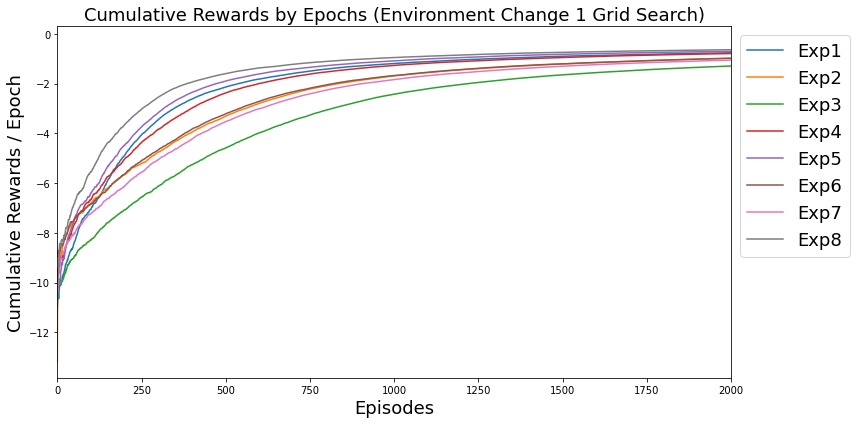

In [532]:
avgcumrewards_e1_1=np.cumsum(np.array(all_rewards_e1[0]))/np.cumsum(np.array(all_epochs_e1[0]))
avgcumrewards_e1_2=np.cumsum(np.array(all_rewards_e1[1]))/np.cumsum(np.array(all_epochs_e1[1]))
avgcumrewards_e1_3=np.cumsum(np.array(all_rewards_e1[2]))/np.cumsum(np.array(all_epochs_e1[2]))
avgcumrewards_e1_4=np.cumsum(np.array(all_rewards_e1[3]))/np.cumsum(np.array(all_epochs_e1[3]))
avgcumrewards_e1_5=np.cumsum(np.array(all_rewards_e1[4]))/np.cumsum(np.array(all_epochs_e1[4]))
avgcumrewards_e1_6=np.cumsum(np.array(all_rewards_e1[5]))/np.cumsum(np.array(all_epochs_e1[5]))
avgcumrewards_e1_7=np.cumsum(np.array(all_rewards_e1[6]))/np.cumsum(np.array(all_epochs_e1[6]))
avgcumrewards_e1_8=np.cumsum(np.array(all_rewards_e1[7]))/np.cumsum(np.array(all_epochs_e1[7]))



fig=plt.figure(figsize=(12,6),tight_layout=True)
ax1=fig.add_subplot()
#ax1.plot(np.array(dropoff_rewards_e1_f_pos),'+b')
#ax1.plot(np.array(pickup_rewards_e1_f_pos),'+g')
ax1.plot(avgcumrewards_e1_1,label='Exp1')
ax1.plot(avgcumrewards_e1_2,label='Exp2')
ax1.plot(avgcumrewards_e1_3,label='Exp3')
ax1.plot(avgcumrewards_e1_4,label='Exp4')
ax1.plot(avgcumrewards_e1_5,label='Exp5')
ax1.plot(avgcumrewards_e1_6,label='Exp6')
ax1.plot(avgcumrewards_e1_7,label='Exp7')
ax1.plot(avgcumrewards_e1_8,label='Exp8')
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_xlim([0,2000])
ax1.set_ylabel("Cumulative Rewards / Epoch",fontsize=18)
ax1.legend(loc=2,fontsize=18,bbox_to_anchor=(1, 1))
plt.title("Cumulative Rewards by Epochs (Environment Change 1 Grid Search)",fontsize=18)
plt.show()

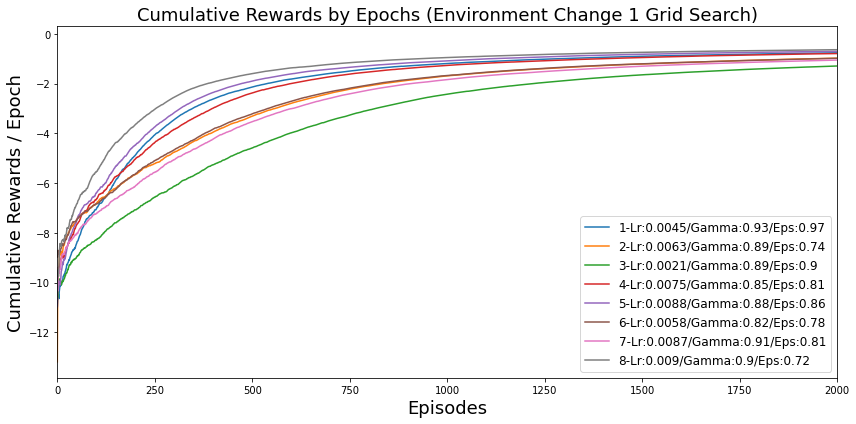

In [546]:
avgcumrewards_e1_1=np.cumsum(np.array(all_rewards_e1[0]))/np.cumsum(np.array(all_epochs_e1[0]))
avgcumrewards_e1_2=np.cumsum(np.array(all_rewards_e1[1]))/np.cumsum(np.array(all_epochs_e1[1]))
avgcumrewards_e1_3=np.cumsum(np.array(all_rewards_e1[2]))/np.cumsum(np.array(all_epochs_e1[2]))
avgcumrewards_e1_4=np.cumsum(np.array(all_rewards_e1[3]))/np.cumsum(np.array(all_epochs_e1[3]))
avgcumrewards_e1_5=np.cumsum(np.array(all_rewards_e1[4]))/np.cumsum(np.array(all_epochs_e1[4]))
avgcumrewards_e1_6=np.cumsum(np.array(all_rewards_e1[5]))/np.cumsum(np.array(all_epochs_e1[5]))
avgcumrewards_e1_7=np.cumsum(np.array(all_rewards_e1[6]))/np.cumsum(np.array(all_epochs_e1[6]))
avgcumrewards_e1_8=np.cumsum(np.array(all_rewards_e1[7]))/np.cumsum(np.array(all_epochs_e1[7]))



fig=plt.figure(figsize=(12,6),tight_layout=True)
ax1=fig.add_subplot()
#ax1.plot(np.array(dropoff_rewards_e1_f_pos),'+b')
#ax1.plot(np.array(pickup_rewards_e1_f_pos),'+g')
ax1.plot(avgcumrewards_e1_1,label='1-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[0], discount_factors_e1[0], epsilon_e1[0]))
ax1.plot(avgcumrewards_e1_2,label='2-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[1], discount_factors_e1[1], epsilon_e1[1]))
ax1.plot(avgcumrewards_e1_3,label='3-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[2], discount_factors_e1[2], epsilon_e1[2]))
ax1.plot(avgcumrewards_e1_4,label='4-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[3], discount_factors_e1[3], epsilon_e1[3]))
ax1.plot(avgcumrewards_e1_5,label='5-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[4], discount_factors_e1[4], epsilon_e1[4]))
ax1.plot(avgcumrewards_e1_6,label='6-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[5], discount_factors_e1[5], epsilon_e1[5]))
ax1.plot(avgcumrewards_e1_7,label='7-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[6], discount_factors_e1[6], epsilon_e1[6]))
ax1.plot(avgcumrewards_e1_8,label='8-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e1[7], discount_factors_e1[7], epsilon_e1[7]))
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_xlim([0,2000])
ax1.set_ylabel("Cumulative Rewards / Epoch",fontsize=18)
ax1.legend(loc=4,fontsize=12)
plt.title("Cumulative Rewards by Epochs (Environment Change 1 Grid Search)",fontsize=18)
#plt.rc('legend', fontsize=8) 
plt.show()

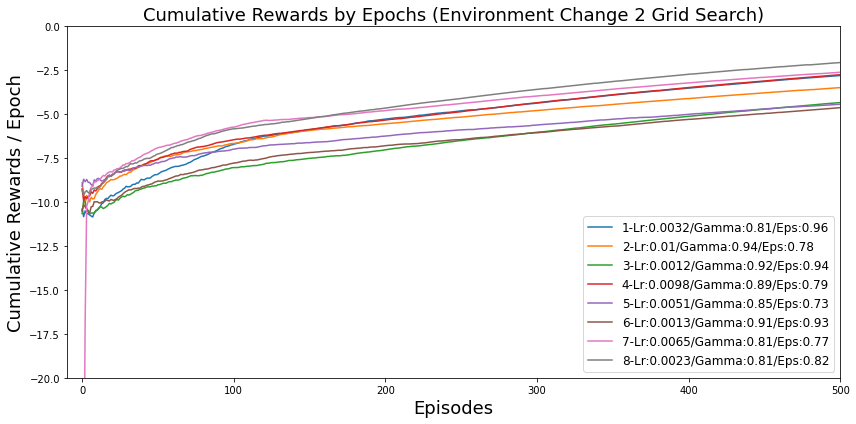

In [557]:
avgcumrewards_e2_1=np.cumsum(np.array(all_rewards_e2[0]))/np.cumsum(np.array(all_epochs_e2[0]))
avgcumrewards_e2_2=np.cumsum(np.array(all_rewards_e2[1]))/np.cumsum(np.array(all_epochs_e2[1]))
avgcumrewards_e2_3=np.cumsum(np.array(all_rewards_e2[2]))/np.cumsum(np.array(all_epochs_e2[2]))
avgcumrewards_e2_4=np.cumsum(np.array(all_rewards_e2[3]))/np.cumsum(np.array(all_epochs_e2[3]))
avgcumrewards_e2_5=np.cumsum(np.array(all_rewards_e2[4]))/np.cumsum(np.array(all_epochs_e2[4]))
avgcumrewards_e2_6=np.cumsum(np.array(all_rewards_e2[5]))/np.cumsum(np.array(all_epochs_e2[5]))
avgcumrewards_e2_7=np.cumsum(np.array(all_rewards_e2[6]))/np.cumsum(np.array(all_epochs_e2[6]))
avgcumrewards_e2_8=np.cumsum(np.array(all_rewards_e2[7]))/np.cumsum(np.array(all_epochs_e2[7]))



fig=plt.figure(figsize=(12,6),tight_layout=True)
ax1=fig.add_subplot()
#ax1.plot(np.array(dropoff_rewards_e1_f_pos),'+b')
#ax1.plot(np.array(pickup_rewards_e1_f_pos),'+g')
ax1.plot(avgcumrewards_e2_1,label='1-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[0], discount_factors_e2[0], epsilon_e2[0]))
ax1.plot(avgcumrewards_e2_2,label='2-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[1], discount_factors_e2[1], epsilon_e2[1]))
ax1.plot(avgcumrewards_e2_3,label='3-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[2], discount_factors_e2[2], epsilon_e2[2]))
ax1.plot(avgcumrewards_e2_4,label='4-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[3], discount_factors_e2[3], epsilon_e2[3]))
ax1.plot(avgcumrewards_e2_5,label='5-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[4], discount_factors_e2[4], epsilon_e2[4]))
ax1.plot(avgcumrewards_e2_6,label='6-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[5], discount_factors_e2[5], epsilon_e2[5]))
ax1.plot(avgcumrewards_e2_7,label='7-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[6], discount_factors_e2[6], epsilon_e2[6]))
ax1.plot(avgcumrewards_e2_8,label='8-Lr:{}/Gamma:{}/Eps:{}'.format(lr_e2[7], discount_factors_e2[7], epsilon_e2[7]))
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_xlim([-10,500])
ax1.set_ylim([-20,0])
ax1.set_ylabel("Cumulative Rewards / Epoch",fontsize=18)
ax1.legend(loc=4,fontsize=12)
plt.title("Cumulative Rewards by Epochs (Environment Change 2 Grid Search)",fontsize=18)
#plt.rc('legend', fontsize=8) 
plt.show()

# Policies evaluation

Now we are going to evaluate the best hyperparameters found against 3 different policies


#### 1) Epsilon greedy policy without decay rate: alpha=0.9,gamma=0.8,epsilon=0.5
#### 2) Epsilon greedy policy with decay rate: alpha=0.9,gamma=0.8,epsilon=0.5, epsilon decay = 0.95
#### 3) Softmax policy:
    

### 1) Epsilon greedy policy (no decay)

In [404]:
%%time
"""Training the agent"""

"""Grid Search Parameters:""

Alpha Values: 0.9,0.1
Gamma Values: 0.8,0.5
Epsilon Values: 0.9,0.5

"""
from IPython.display import clear_output

lr = 0.9
discount_factor = 0.8
epsilon = 0.5

env = MapWalkingEnv(10,10)

all_epochs_p1, all_rewards_p1, aggr_ep_rewards_p1 = \
QLearning(env, num_episodes=100000, lr=lr, discount_factors=discount_factor, \
epsilon=epsilon, epsilon_decay=0, display_mode=False, policy='epsilon_greedy', temp=0)

Training finished.

Wall time: 22min 9s


In [391]:
all_rewards_p2

[-160,
 -1630,
 -1610,
 -1300,
 -1230,
 -1120,
 -410,
 -1020,
 -910,
 -1030,
 -1120,
 -1220,
 -970,
 -1300,
 -810,
 -1080,
 -970,
 -500,
 -1060,
 -910,
 -970,
 -220,
 -960,
 -790,
 -1080,
 -1220,
 -1120,
 -100,
 -1030,
 -830,
 -1100,
 -580,
 -1070,
 -1050,
 -1050,
 -1420,
 -590,
 -940,
 -810,
 -260,
 -1270,
 -1280,
 -590,
 -900,
 -950,
 -750,
 -390,
 -980,
 -1020,
 -1150,
 -710,
 -460,
 -1170,
 -990,
 -1030,
 -180,
 -1070,
 -320,
 -790,
 -1170,
 -1190,
 -910,
 -940,
 -1470,
 -860,
 -1040,
 -1020,
 -610,
 -1210,
 -1150,
 -600,
 -1040,
 -1020,
 -430,
 -370,
 -1000,
 -890,
 -930,
 -650,
 -540,
 -1170,
 -820,
 -870,
 -660,
 -910,
 -1480,
 -870,
 -1080,
 -1140,
 -740,
 -1140,
 -1010,
 -980,
 -1370,
 -1020,
 -440,
 -890,
 -940,
 -810,
 -1020,
 -950,
 -950,
 -410,
 -930,
 -1380,
 -690,
 -1080,
 -870,
 -780,
 -800,
 -650,
 -760,
 -1200,
 -160,
 -1000,
 -850,
 -1240,
 -970,
 -950,
 -310,
 -1130,
 -1170,
 -820,
 -1170,
 -1160,
 -1020,
 -840,
 -1290,
 -1120,
 -1110,
 -920,
 -1110,
 -840,
 -870,
 

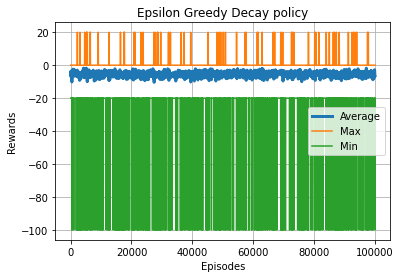

No handles with labels found to put in legend.


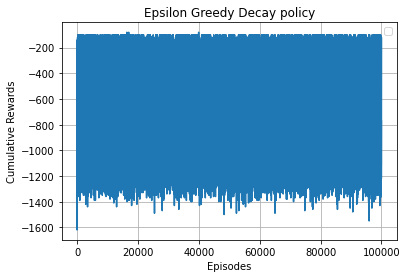

In [406]:
plt.plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['avg'], linewidth=3, label="Average")
plt.plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['max'], label="Max")
plt.plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['min'], label="Min")
plt.legend(loc=0)
plt.title('Epsilon Greedy (No Decay) policy')
plt.xlabel('Episodes')
plt.ylabel('Rewards')
plt.grid(True)
plt.show()

plt.plot(all_rewards_p1)
plt.legend(loc=0)
plt.title('Epsilon Greedy (No Decay) policy')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Rewards')
plt.grid(True)
plt.show()

In [322]:
all_rewards

[-1610, -1870, -410, -1830, -790, -1780, -1740, -1680, -1480]

### 2) Epsilon greedy policy (with decay)

In [405]:
#alpha=0.9,gamma=0.8,epsilon=0.5 epsilon decay = 0.95 
# Taken from Tune 4 parameters
lr = 0.9
discount_factor = 0.8
epsilon = 0.5
epsilon_decay = 0.95

env = MapWalkingEnv(10,10)

all_epochs_p2, all_rewards_p2, aggr_ep_rewards_p2 = \
QLearning(env, num_episodes=100000, lr=lr, discount_factors=discount_factor, \
epsilon=epsilon, epsilon_decay=0.9998, display_mode=False, policy='epsilon_greedy_decay', temp=0)

In [376]:
99000/50

1980.0

In [379]:
aggr_ep_rewards_p2['min'][1990]

-20

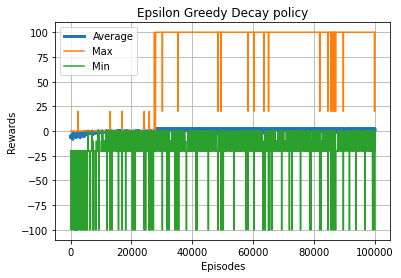

No handles with labels found to put in legend.


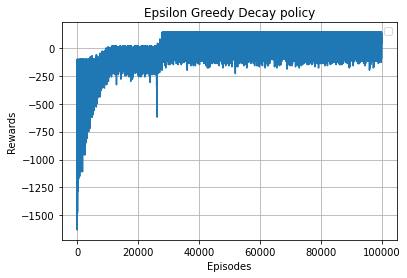

In [397]:
plt.plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['avg'], linewidth=3, label="Average")
plt.plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['max'], label="Max")
plt.plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['min'], label="Min")
plt.legend(loc=0)
plt.title('Epsilon Greedy Decay policy')
plt.xlabel('Episodes')
plt.ylabel('Rewards')
plt.grid(True)
plt.show()

plt.plot(all_rewards_p2)
plt.legend(loc=0)
plt.title('Epsilon Greedy Decay policy')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Rewards')
plt.grid(True)
plt.show()

### 3) Softmax policy

In [386]:
env.action_space

7

In [402]:
lr = 0.9
discount_factor = 0.8
temp = 3.0

env = MapWalkingEnv(10,10)

all_epochs_p3, all_rewards_p3, aggr_ep_rewards_p3 = \
QLearning(env, num_episodes=100000, lr=lr, discount_factors=discount_factor, \
epsilon=0, epsilon_decay=0, display_mode=False, policy='softmax', temp=temp)

Training finished.



### Evaluation

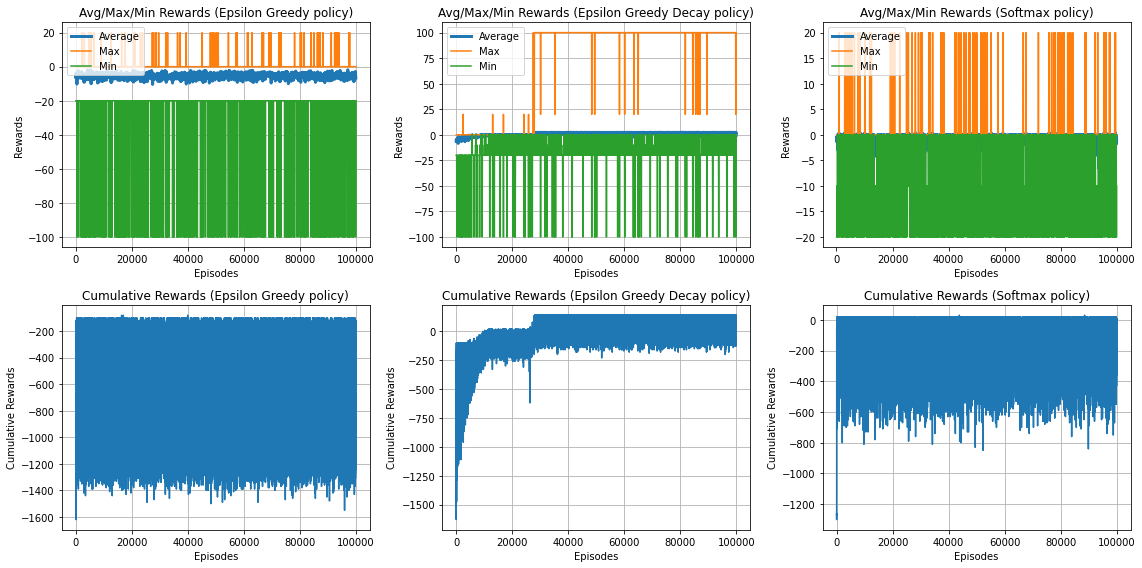

In [507]:
# using the variable axs for multiple Axes
fig, axs = plt.subplots(2, 3, figsize=(16,8))

axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['avg'], linewidth=3, label="Average")
axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['max'], label="Max")
axs[0, 0].plot(aggr_ep_rewards_p1['ep'], aggr_ep_rewards_p1['min'], label="Min")
axs[0, 0].legend(loc="upper left")
axs[0, 0].set_title('Avg/Max/Min Rewards (Epsilon Greedy policy)')
axs[0, 0].set_xlabel('Episodes')
axs[0, 0].set_ylabel('Rewards')
axs[0, 0].grid(True)
#plt.show()

axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['avg'], linewidth=3, label="Average")
axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['max'], label="Max")
axs[0, 1].plot(aggr_ep_rewards_p2['ep'], aggr_ep_rewards_p2['min'], label="Min")
axs[0, 1].legend(loc="upper left")
axs[0, 1].set_title('Avg/Max/Min Rewards (Epsilon Greedy Decay policy)')
axs[0, 1].set_xlabel('Episodes')
axs[0, 1].set_ylabel('Rewards')
axs[0, 1].grid(True)
#plt.show()

axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['avg'], linewidth=3, label="Average")
axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['max'], label="Max")
axs[0, 2].plot(aggr_ep_rewards_p3['ep'], aggr_ep_rewards_p3['min'], label="Min")
axs[0, 2].legend(loc="upper left")
axs[0, 2].set_title('Avg/Max/Min Rewards (Softmax policy)')
axs[0, 2].set_xlabel('Episodes')
axs[0, 2].set_ylabel('Rewards')
plt.grid(True)
#plt.show()

axs[1, 0].plot(all_rewards_p1)
axs[1, 0].set_title('Cumulative Rewards (Epsilon Greedy policy)')
axs[1, 0].set_xlabel('Episodes')
axs[1, 0].set_ylabel('Cumulative Rewards')
axs[1, 0].grid(True)
#plt.show()

axs[1, 1].plot(all_rewards_p2)
axs[1, 1].set_title('Cumulative Rewards (Epsilon Greedy Decay policy)')
axs[1, 1].set_xlabel('Episodes')
axs[1, 1].set_ylabel('Cumulative Rewards')
axs[1, 1].grid(True)
#plt.show()

axs[1, 2].plot(all_rewards_p3)
axs[1, 2].set_title('Cumulative Rewards (Softmax policy)')
axs[1, 2].set_xlabel('Episodes')
axs[1, 2].set_ylabel('Cumulative Rewards')
axs[1, 2].grid(True)
#plt.show()

fig.tight_layout()
plt.show()


In [558]:
AllSearchResults2=pd.read_csv('AllSearchResults2.csv')
AllSearchResults2

,Base,Tune1,Tune2,Tune3,Tune4
0,-11.666667,-10.000000,-8.150000,-11.056338,-7.600000
1,-10.467626,-11.777778,-8.100000,-10.292398,-7.700000
2,-10.292887,-9.795918,-7.383333,-9.797048,-8.058036
3,-10.235988,-9.820225,-6.662500,-9.797844,-8.376866
4,-10.318907,-9.736434,-6.827309,-9.628450,-7.622283
...,...,...,...,...,...
99994,-1.253730,-1.392662,-0.957686,-1.303291,-0.806985
99995,-1.253741,-1.392653,-0.957678,-1.303281,-0.806984
99996,-1.253731,-1.392644,-0.957672,-1.303265,-0.806975
99997,-1.253721,-1.392636,-0.957663,-1.303253,-0.806967


In [575]:
AllSearchResults2_Results = AllSearchResults2.loc[99000:,:]

AllSearchResults2_Results.mean()

Base    -1.257634
Tune1   -1.396287
Tune2   -0.960491
Tune3   -1.306931
Tune4   -0.809411
dtype: float64

In [574]:
AllSearchResults2_Results = AllSearchResults2.loc[99000:,:]

AllSearchResults2_Results.std()

Base     0.002189
Tune1    0.002154
Tune2    0.001583
Tune3    0.002112
Tune4    0.001364
dtype: float64

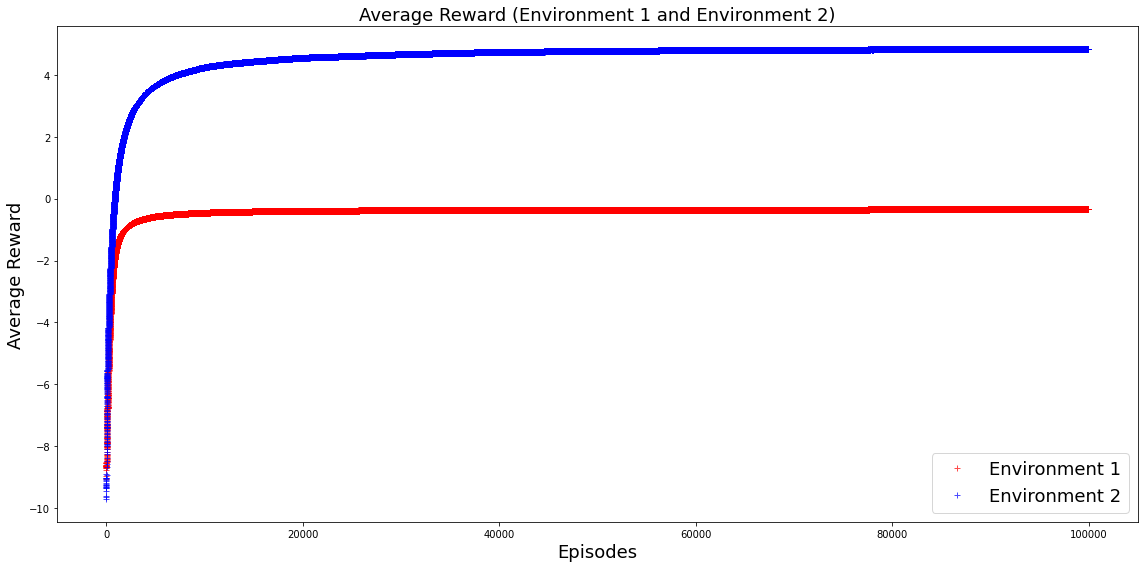

In [580]:
#Can use AllSearchResults for historic plots
avgcumrewardsEnv1=np.cumsum(np.array(all_rewards_e1_f))/np.cumsum(np.array(all_epochs_e1_f))
avgcumrewardsEnv2=np.cumsum(np.array(all_rewards_e2_f))/np.cumsum(np.array(all_epochs_e2_f))
#avgrewardTune4=np.array(all_rewards)/np.array(all_epochs)
Tune3Output=pd.DataFrame(avgcumrewardsTune3)
fig=plt.figure(figsize=(16,8),tight_layout=True)
ax1=fig.add_subplot()
#ax1.plot(Tune3Output[0],'b',label ='TestRun')
ax1.plot(avgcumrewardsEnv1,'+r',label ='Environment 1', alpha=0.7)
ax1.plot(avgcumrewardsEnv2,'+b',label ='Environment 2', alpha=0.7)
ax1.set_xlabel("Episodes",fontsize=18)
ax1.set_ylabel("Average Reward",fontsize=18)
#ax1.set_ylim([-10,0])
ax1.legend(loc=4,fontsize=18)
plt.title("Average Reward (Environment 1 and Environment 2)",fontsize=18)
plt.show()

## Epochs

In [582]:
#Cum Pickup
cumpickup1=np.cumsum(np.array(pickup_epochs_e1_f))
cumpickup1=pd.DataFrame(cumpickup1)
cumpickup1['MA'] = 1
cumpickup1['MACUM'] =np.cumsum(cumpickup1['MA'])
cumpickup1['PUCUMAVG']= cumpickup1[0] / cumpickup1['MACUM']
# Cum Drop Off
cumdropoff1=np.cumsum(np.array(dropoff_epochs_e1_f))
cumdropoff1=pd.DataFrame(cumdropoff1)
cumdropoff1['MA'] = 1
cumdropoff1['MACUM'] =np.cumsum(cumdropoff1['MA'])
cumdropoff1['DOCUMAVG']= cumdropoff1[0] / cumdropoff1['MACUM']
# Cum Open
cumopen1=np.cumsum(np.array(open_epochs_e1_f))
cumopen1=pd.DataFrame(cumopen1)
cumopen1['MA'] = 1
cumopen1['MACUM'] =np.cumsum(cumopen1['MA'])
cumopen1['OPCUMAVG']= cumopen1[0] / cumopen1['MACUM']
cumopen1['test']=cumopen1[0].diff().fillna(cumopen1[0])

#Cum Pickup
cumpickup2=np.cumsum(np.array(pickup_epochs_e2_f))
cumpickup2=pd.DataFrame(cumpickup2)
cumpickup2['MA'] = 1
cumpickup2['MACUM'] =np.cumsum(cumpickup2['MA'])
cumpickup2['PUCUMAVG']= cumpickup2[0] / cumpickup2['MACUM']
# Cum Drop Off
cumdropoff2=np.cumsum(np.array(dropoff_epochs_e2_f))
cumdropoff2=pd.DataFrame(cumdropoff2)
cumdropoff2['MA'] = 1
cumdropoff2['MACUM'] =np.cumsum(cumdropoff2['MA'])
cumdropoff2['DOCUMAVG']= cumdropoff2[0] / cumdropoff2['MACUM']
# Cum Open
cumopen2=np.cumsum(np.array(open_epochs_e2_f))
cumopen2=pd.DataFrame(cumopen2)
cumopen2['MA'] = 1
cumopen2['MACUM'] =np.cumsum(cumopen2['MA'])
cumopen2['OPCUMAVG']= cumopen2[0] / cumopen2['MACUM']
cumopen2['test']=cumopen2[0].diff().fillna(cumopen2[0])



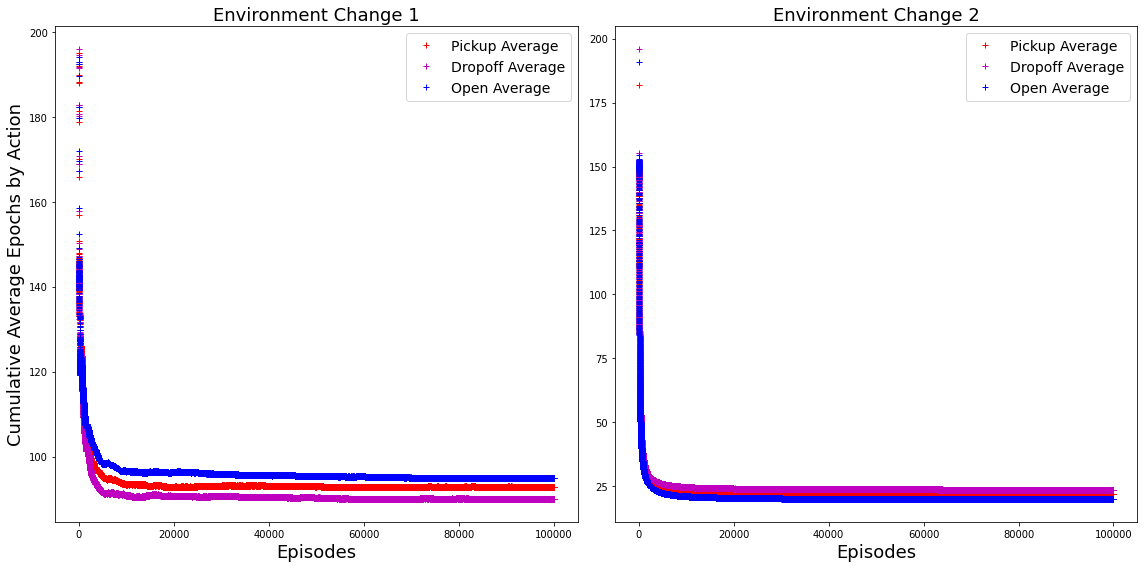

In [590]:
#Cumulative Epochs by Action
fig, axs=plt.subplots(1,2,figsize=(16,8),tight_layout=True)
#axs[0]=fig.add_subplot()
axs[0].plot(cumpickup1['PUCUMAVG'].head(150000),'+r',label ='Pickup Average')
axs[0].plot(cumdropoff1['DOCUMAVG'].head(150000),'+m',label ='Dropoff Average')
axs[0].plot(cumopen1['OPCUMAVG'].head(150000),'+b',label ='Open Average')
axs[1].plot(cumpickup2['PUCUMAVG'].head(150000),'+r',label ='Pickup Average')
axs[1].plot(cumdropoff2['DOCUMAVG'].head(150000),'+m',label ='Dropoff Average')
axs[1].plot(cumopen2['OPCUMAVG'].head(150000),'+b',label ='Open Average')


axs[0].set_xlabel("Episodes",fontsize=18)
axs[1].set_xlabel("Episodes",fontsize=18)
axs[0].set_ylabel("Cumulative Average Epochs by Action",fontsize=18)
axs[0].legend(loc=1,fontsize=14)
axs[1].legend(loc=1,fontsize=14)
axs[0].set_title("Environment Change 1",fontsize=18)
axs[1].set_title("Environment Change 2",fontsize=18)
plt.show()
#Essentially takes longer to figure out where to drop off as immediate rewards are more likely to come from picking up
#and opening doors?

In [592]:
from environment_hostage_update import MapWalkingEnvHostUpdate 

In [593]:
env = MapWalkingEnvHostUpdate(10,10)
env.reset()
env.display()

Key (Yellow): 0 / Door (Blue): 0 / Hostage (Green): 0 - Agent start (9, 6)
. X . . . . . H S M 
. . . . . X . . . . 
. . . . . X . . . . 
X X . X X . X . . . 
. . X . X . X X X . 
. . X . X . . K . . 
. . . . . . . . . . 
. . . . . . X X X X 
. X X X X X . . . . 
. . . . . . A X . U 

